# Lab1: Efficient AI Fundamentals

**中文学习说明：从“模型能运行”走向“理解模型为什么快或慢”。**

Lab 0 关注训练：输入图片、计算损失、更新参数。本实验关注效率：一次计算花多久、做多少运算、搬运多少数据，以及 GPU 的时间具体花在哪里。这里主要使用随机输入和随机初始化的模型做性能实验，不是在训练或验证语言模型的回答质量。

建议按 **小矩阵乘法 → 延迟/MAC/I/O → 屋顶线 → MLP 与注意力 → 性能分析 → 编译与 Flash Attention** 的顺序阅读。第 3 部分的大段模型定义可以先看各模块的作用，再跟着后面的单独例子理解。

**运行前先看这几条：**

- 在 VS Code 选择已安装本实验依赖的 Python 内核，安装说明见 [README](README.md)。工作目录应设为 `lab1_gpu_basics`，这样 `from utils import *` 和图片相对路径才能找到本实验文件。
- 从上到下运行，单元格共享变量。`NameError` 常表示漏跑了前面的定义；重启内核后需要重新执行依赖的单元格。
- `YOUR CODE HERE` 和 `raise NotImplementedError()` 是原课留下的练习位置。本版已补全全部代码练习和参考问答；新增代码使用【已补全】标记，运行所需的必要修正使用【辅助修正】标记。
- 开头设置 `device="cpu"` 仅能让部分普通张量代码使用 CPU。后面的 CUDA 事件、显存统计、硬编码 `device="cuda"` 的实验需要可用的 NVIDIA GPU。第 3.3 节默认输入较大，第 5 部分还需要相应硬件和依赖。

**先记住这些形状符号：**

| 符号 | 含义 | 怎样理解 |
| --- | --- | --- |
| `B` | batch size，批大小 | 同时处理几条样本 |
| `L`、`L_q`、`L_kv` | 序列长度、查询长度、键值长度 | 本次处理或可访问多少个 token |
| `D` | hidden size，隐藏维度 | 每个 token 有多少个特征 |
| `I` | MLP 中间维度 | 前馈网络扩展后的特征数量 |
| `H` | 通常表示注意力头数 | 个别函数用它表示隐藏维度，要看局部赋值 |
| `D_h` | head dimension，每头维度 | 每个注意力头有多少个特征 |

`[B, L, D]` 可以理解为“B 条序列，每条 L 个 token，每个 token 用 D 个数表示”。token 是模型处理的文本单位，不一定对应一个汉字或一个完整单词。

阅读代码时，逐行问自己：**这是什么 Python 写法？输入输出是什么形状？执行了什么计算或改变了什么状态？这里为什么需要它？**

In this lab, you will learn the foundational concepts of efficient AI through hands-on analysis of an LLM decoder layer.

## Learning Objectives

By the end of this lab, you will be able to:

1. **Measure latency, calculate MAC/FLOPs, and compute I/O cost** for your deep learning algorithms
2. **Use roofline models** to identify performance bottlenecks (compute or I/O)
3. **Profile kernel launches on GPU** using PyTorch Profiler
4. **Understand kernel launch overhead** and optimization techniques (kernel fusion, torch.compile, CUDA Graphs)
5. **Analyze Flash Attention** and explain why it's faster

**【本版完成说明】** 所有代码练习、Bonus 代码和参考问答均已补全。搜索 `【已补全】` 可以定位解答，搜索 `【辅助修正】` 可以定位为实际运行增加的支持代码。默认 `LEARNING_MODE=True` 使用小输入，原题的大规模参数保留在对应分支中。A6000 屋顶线是原题理论参考，实测则使用当前选定设备，二者分别标注。

基础依赖仍需安装到你实际选择的 Python 内核；可在该内核中执行 `%pip install "transformers==4.57.6" "tokenizers==0.22.2" "huggingface_hub==0.36.2" "accelerate==1.11.0"`，完成后重启内核。编译与独立 Flash 包为可选实验支持，本版会如实显示是否运行。


**【本版验证状态·2026-11-16】**

已在独立验证环境使用 **NVIDIA GeForce RTX 4060 Laptop GPU / PyTorch 2.6.0+cu126**，从头执行 45 个代码单元格，保留了实际输出与图表。原题公开检查、CPU/GPU 矩形注意力和掩码检查、GeLU 数值/梯度检查均通过；缓存路径另外通过 FP32 一致性检查。

| 项目 | 本次结果 |
| --- | --- |
| 代码练习、Bonus、参考问答 | 全部补全，新增内容有明确标记 |
| 延迟与标准注意力显存 | 已在学习配置下实际测量 |
| GPU 内核采集 | 当前 Profiler 仅支持 CPU 活动，CUDA 内核时间线和次数未采集 |
| torch.compile / CUDA Graphs 编译实验 | 缺少兼容 Triton，明确跳过 |
| Flash Attention | 独立包未安装，且当前 PyTorch 构建未编入 Flash 内核；未获得 Flash 实测结果 |
| 大规模 OOM 阈值 | 学习模式预先跳过超大分配，未测得精确阈值 |

验证使用的隔离环境不会替你给当前 AI 内核安装基础依赖。要在自己的内核重跑，先执行本页开头的固定依赖安装命令，然后重启内核。时间线文件在 [outputs](outputs/) 中；当前文件里的这些 trace 是 CPU 活动记录。


In [1]:
import torch  # 导入 PyTorch，后面用 torch 创建张量、执行计算和访问 CUDA。
import torch.nn as nn  # 导入神经网络模块并起别名 nn，后面用 nn.Module、nn.Linear 构造模型。
import torch.nn.functional as F  # 导入函数式接口并起别名 F，例如 F.gelu 直接计算激活函数。
from torch.profiler import profile, ProfilerActivity  # 直接引入性能分析器和活动类型，后面可用 profile(...) 创建分析上下文。
import matplotlib.pyplot as plt  # 导入绘图模块并起别名 plt，用于显示曲线和图表。
import numpy as np  # 导入 NumPy 并起别名 np，后面用它创建屋顶线曲线上的数值点。
import pandas as pd  # 导入 pandas 并起别名 pd，后面把多次实验结果整理成表格。
from typing import Dict, List, Tuple, Optional  # 引入类型注解工具；Optional[T] 表示允许 T 类型或 None，注解本身不执行类型检查。
import warnings  # 导入 Python 的警告管理模块；警告和会中断执行的异常是两回事。
warnings.filterwarnings('ignore')  # 默认隐藏警告，让实验输出简洁；排查问题时需要关注被隐藏的信息。
warnings.filterwarnings('default', module='torch._inductor')  # 单独恢复编译后端相关的警告，便于发现 torch.compile 的问题。

# 导入本实验附带的工具函数与配置。
import sys  # 导入系统模块，后面用 sys.path 调整 Python 寻找模块的位置。
# 【辅助修正】同时支持从项目根目录和本实验目录启动。
from pathlib import Path  # 用于定位当前实验自带的 utils。
lab_dir = Path.cwd()  # 读取内核工作目录。
if (lab_dir / "lab1_gpu_basics" / "utils").is_dir():  # 从项目根目录启动时找到实验子目录。
    lab_dir = lab_dir / "lab1_gpu_basics"  # 转到本实验的模块目录。
sys.path.insert(0, str(lab_dir))  # 把实际实验目录加入模块搜索路径。
from utils import *  # 引入本实验 utils 中对外提供的工具和配置；可到 utils/__init__.py 查看具体名称。

# 检查当前环境是否能够使用 CUDA GPU。
print(f"PyTorch version: {torch.__version__}")  # f 字符串把花括号中的 PyTorch 版本嵌入文字并打印。
print(f"CUDA available: {torch.cuda.is_available()}")  # 打印当前 PyTorch 是否能使用 CUDA；安装了包并不代表 GPU 一定可用。
if torch.cuda.is_available():  # 如果 CUDA 可用，就执行下面缩进的 GPU 初始化代码。
    device = torch.device("cuda")  # 创建 GPU 设备描述；后面创建张量或移动模型时用它指定设备。
    print(f"GPU: {torch.cuda.get_device_name(0)}")  # 打印第 0 块 GPU 的名称，GPU 的编号从 0 开始。
    print(f"GPU Memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")  # 把显卡总显存字节数除以十亿换成十进制 GB；:.1f 保留一位小数。
else:  # 上面的 if 条件不成立时，执行这个分支；具体含义要结合所在代码块阅读。
    device = torch.device("cpu")  # 设置 CPU 设备；后续直接调用 CUDA 的单元格仍需要 GPU，不能因此全部在 CPU 上运行。

# 16-bit dtype for Part 4: bf16 on GPUs with native bf16 support (compute capability >= 8.0), fp16 otherwise (e.g. the Colab T4)
half_dtype = torch.bfloat16 if torch.cuda.is_available() and torch.cuda.get_device_capability()[0] >= 8 else torch.float16  # 条件表达式选择 16 位类型；and 会短路求值，CUDA 不可用时不会继续查询 GPU 能力。
print(f"Part 4 dtype: {half_dtype}")  # 打印第 4 部分将使用的数值类型；dtype 决定每个元素的存储格式。


# ===== 【辅助修正】统一实验配置与分析工具 =====
import importlib.util  # 用于检查可选编译后端是否安装。
from pathlib import Path  # 用来构造导出 trace 的路径。

LEARNING_MODE = True  # 学习模式使用小输入；改为 False 可恢复原题的大规模实验。
torch.manual_seed(0)  # 固定随机起点，便于在相同环境下复查数值；延迟仍会随系统负载波动。
lab_output_dir = lab_dir / "outputs"  # 实测记录与 trace 导出到本实验目录的 outputs 文件夹。
lab_output_dir.mkdir(exist_ok=True)  # 创建目录；已经存在则直接复用。
compile_status = {}  # 保存编译成功或未运行的原因，避免把未测当作测量结果。
print("Profiler 可采集的活动：", torch.profiler.supported_activities())  # CUDA 可计算不代表当前构建具备 CUDA 事件采集支持。
print("当前 PyTorch 是否编入 Flash 内核：", torch.backends.cuda.is_flash_attention_available())  # 检查二进制支持，而不只检查 GPU 型号。

def profile_for_lab(fn, *args, trace_name, **kwargs):  # 统一预热、正式记录和 trace 导出。
    activities = [ProfilerActivity.CPU]  # CPU 事件帮助观察 Python 提交与调度。
    has_cuda_capture = ProfilerActivity.CUDA in torch.profiler.supported_activities()  # 检查当前构建真正支持的分析活动。
    if has_cuda_capture:  # 只有采集接口支持 CUDA 时才请求设备事件。
        activities.append(ProfilerActivity.CUDA)  # 请求记录 GPU 活动。
    elif torch.cuda.is_available():  # GPU 可以执行计算，但当前分析器只支持 CPU 活动。
        print("【采集限制】本次 trace 仅含 CPU 操作与提交；CUDA 内核时间线和调用数没有被采集。")  # 不把缺失数据写成零次GPU计算。
    with torch.no_grad():  # 性能实验只做前向，不保存反向传播图。
        for _ in range(3):  # 先在记录区域之外预热。
            fn(*args, **kwargs)  # 用与正式测量相同的参数执行。
        if torch.cuda.is_available():  # 等待所有预热工作完成。
            torch.cuda.synchronize()  # 防止预热混入 active 窗口。
        with profile(activities=activities, schedule=default_schedule) as prof:  # 使用等待1、预热3、记录6的日程。
            for _ in range(10):  # 10 步恰好覆盖整个日程。
                fn(*args, **kwargs)  # 真正执行待分析的前向调用。
                prof.step()  # 向分析器报告本步完成。
            if torch.cuda.is_available():  # 退出前等待最后的设备工作。
                torch.cuda.synchronize()  # 使分析结果完整。
    sort_key = "cuda_time_total" if has_cuda_capture else "cpu_time_total"  # 按真正采集到的活动选择排序列。
    print(prof.key_averages().table(sort_by=sort_key, row_limit=20))  # 打印主要耗时操作。
    trace_path = lab_output_dir / f"{trace_name}.json"  # 为本次实验使用独立文件名。
    prof.export_chrome_trace(str(trace_path))  # 导出可供 Perfetto 打开的时间线。
    print("时间线文件：", trace_path)  # 打印真实写入位置。
    if torch.cuda.is_available() and count_cuda_kernels(prof)["total"] == 0:  # 某些环境可能缺少 CUDA 事件采集支持。
        print("【采集限制】未记录到 CUDA 内核；可读 CPU 事件，但不能据此推断 GPU 内核为零。")  # 明确解释采集缺口。
    return prof  # 返回分析器，供调用方继续统计内核和查看事件。

def prepare_compiled(fn, sample, *, name, mode="default"):  # 将首次编译与稳定性能分析分开。
    if device.type == "cuda" and importlib.util.find_spec("triton") is None:  # 当前 GPU 编译路径需要兼容的 Triton 支持。
        compile_status[name] = "当前环境没有可用的 Triton，未执行 GPU 编译实验。"  # 保存真实未运行原因。
        return None  # 显式返回缺失状态，不用 eager 结果冒充 compiled。
    try:  # 首次编译可能受系统工具链或硬件支持影响。
        compiled = torch.compile(fn, mode=mode)  # 创建指定模式的编译包装。
        with torch.no_grad():  # 与后续纯前向分析保持一致。
            for _ in range(3):  # 在正式分析前触发编译和若干次预热。
                compiled(sample)  # 实际调用才可能产生主要编译工作。
        if torch.cuda.is_available():  # 等待编译后的设备执行结束。
            torch.cuda.synchronize()  # 在记录成功前确认调用完成。
    except (RuntimeError, ImportError, OSError) as error:  # 捕获并报告编译环境或后端运行失败。
        compile_status[name] = f"编译未成功：{type(error).__name__}: {error}"  # 保留错误，不产生假的实验数据。
        print("【未运行编译对比】", compile_status[name])  # 将失败原因显示给学习者。
        return None  # 后续单元格按 None 显式跳过该项测量。
    compile_status[name] = f"已实际调用并预热，mode={mode}；CUDA Graphs 是否重放仍需看 trace。"  # 不把模式选择当作优化生效证据。
    return compiled  # 返回真实成功运行过的编译对象。


# ===== 【辅助修正】显存对比使用相同口径的峰值新增分配 =====
def extra_peak_memory_gb(fn, *args):  # 测调用期间相对于调用前基线新增的峰值，而不是把所有输入算入结果。
    if not torch.cuda.is_available():  # 这个指标只针对 CUDA 显存。
        raise RuntimeError("显存测量需要 CUDA。")  # CPU 内存不能冒充 GPU 显存。
    with torch.no_grad():  # 只比较前向计算，不保留反向图。
        fn(*args)  # 先预热一次，避免把首次初始化当成主要差异。
        torch.cuda.synchronize()  # 等待预热输出完成和释放。
        baseline = torch.cuda.memory_allocated()  # 记录仍活跃的输入等已有分配。
        torch.cuda.reset_peak_memory_stats()  # 重置峰值统计起点。
        output = fn(*args)  # 保持输出引用，确保结果占用也纳入峰值。
        torch.cuda.synchronize()  # 等待调用完成再读统计。
        extra_bytes = torch.cuda.max_memory_allocated() - baseline  # 扣除已有活跃分配，得到新增峰值。
        del output  # 删除本次输出引用，避免影响下一次测量。
    return extra_bytes / 1e9  # 返回十进制 GB；指标仍不包括所有驱动/外部库分配。


PyTorch version: 2.6.0+cu126
CUDA available: True
GPU: NVIDIA GeForce RTX 4060 Laptop GPU
GPU Memory: 8.6 GB
Part 4 dtype: torch.bfloat16
Profiler 可采集的活动： {<ProfilerActivity.CPU: 0>}
当前 PyTorch 是否编入 Flash 内核： False


# Part 1: Fundamental Metrics — Latency, MAC, and I/O

**中文导读：三个指标分别回答三个问题。**

- **Latency（延迟）**：实际运行一次要多久，通常需要测量。
- **MAC / FLOPs（运算量）**：理论上做了多少次乘加或浮点运算，可以按形状估算。
- **I/O（读写量）**：理论上从显存读入和写回多少字节，可以按元素数量与数据类型估算。

运算量相同的两段程序，实际延迟仍可能不同；数据搬运、并行方式、内核启动和实现效率都会影响结果。

In this section, we will learn three fundamental metrics: latency, MAC, and I/O. We will start with the most common operator, matrix/vector multiplication.

#### Question 1.1 (5 points)

**中文题意：用三重循环实现矩阵乘法。**

若 A 是 `[N, K]`，B 是 `[K, M]`，结果应是 `[N, M]`。先选结果的行、再选列，最后遍历共有的 K 维，把对应乘积累加到这个输出位置。可以先用纸笔算两个 2×2 矩阵，再写循环。

允许用 `.tolist()` 取得普通 Python 列表，并在最后用 `torch.tensor` 建回张量。即使输入原本在 GPU，转换后的列表和 Python 三重循环仍在 CPU 上运行；输出的设备和类型要与输入保持一致。

Please write a tri-loop version of matrix multiplication (please don't use any libraries such as Numpy, Scipy, and PyTorch API for this question)

Note: you may use `.tolist()` to read the inputs and `torch.tensor(..., device=A.device, dtype=A.dtype)` to build the output, as long as the triple loop itself is plain Python. The loop running on the CPU is intended: later you will compare it against the optimized `torch.matmul`.

**【已补全·重点解释】Q1.1：三重循环矩阵乘法**

A[N,K] 与 B[K,M] 相乘，结果 C[N,M]。`i` 选结果的行，`j` 选结果的列，`k` 遍历相乘后要累加的元素：`C[i][j] += A[i][k] * B[k][j]`。

两个 `for` 创建二维列表时，每一行必须独立创建；`[[0] * M] * N` 会让多行引用同一个列表，因此这里使用嵌套列表推导式。`.tolist()` 和最终 `torch.tensor` 在循环外负责数据格式转换，三重循环内使用普通 Python 数字计算。这是 CPU 手写基线，GPU 输入还会包含往返拷贝。

In [2]:
# ===== 【已补全】Q1.1：三重循环矩阵乘法 =====
def gemm(A, B):  # 定义函数：接收两个二维张量，返回它们的矩阵乘积。
    if A.ndim != 2 or B.ndim != 2:  # ndim 是维度数；本练习只处理二维矩阵。
        raise ValueError("gemm 需要两个二维矩阵。")  # 形状不符合要求时给出明确错误。
    N, K = A.shape  # 拆包取得左矩阵的行数 N 和列数 K。
    K_b, M = B.shape  # 右矩阵行数必须与 K 相同，列数决定输出的 M。
    if K != K_b or A.device != B.device or A.dtype != B.dtype:  # 检查共同维度、设备和数据类型。
        raise ValueError("内维度必须相同，且 A/B 的设备和类型必须一致。")  # 避免无意义的计算。
    a_rows = A.tolist()  # 转为 Python 嵌套列表；GPU 输入会在这里复制到 CPU。
    b_rows = B.tolist()  # 同样取得右矩阵的 Python 数字。
    c_rows = [[0.0 for _ in range(M)] for _ in range(N)]  # 独立创建 N 行，每行 M 个累加位置。
    for i in range(N):  # 第一层：依次选择结果的行。
        for j in range(M):  # 第二层：依次选择结果的列。
            for k in range(K):  # 第三层：计算这一行与这一列的点积。
                c_rows[i][j] += a_rows[i][k] * b_rows[k][j]  # 一次乘法并累加，就是一次 MAC。
    return torch.tensor(c_rows, device=A.device, dtype=A.dtype)  # 把结果放回输入设备，并保持数值类型。


## 1.1 Latency

**中文导读：为什么给 GPU 计时要“等待”？**

CPU 调用很多 CUDA 算子时，只是把工作提交给 GPU，然后继续执行 Python；这叫异步执行。因此 Python 执行到下一行时，GPU 不一定已经算完。CUDA Event 在流中记录时间点，`torch.cuda.synchronize()` 等待工作完成后再读取结果。

下面函数中，`fn` 是待测函数对象；`*args` 接收额外的位置参数，`**kwargs` 接收额外的关键字参数。调用 `fn(*args, **kwargs)` 时再把它们展开转交。本版已经修正为同步后的墙钟计时并返回毫秒数，适合当前 CPU 三重循环的端到端测量；CUDA Event 的用法继续在后面的平均计时器中展示。

CUDA Event 适合分析 GPU 流上的工作。本题手写三重循环包含 CPU 执行与可能的数据拷贝，读数不能当成纯 GPU 矩阵乘法性能；若要严格测 CPU 或端到端耗时，可另用 CPU 时钟配合必要的同步。

As simple as it means, latency refers to how long your program takes to execute on your device. It is a basic yet important metric for efficiency evaluation. Below is a standard way to measure latency on GPU. Below is code for evaluating a function execution one time.

**【辅助修正·重点解释】单次计时要返回读数**

手写三重循环在 CPU 上执行，因此用 `time.perf_counter()` 测同步后的端到端墙钟时间更合适。计时前同步，避免把上一段 GPU 工作算进来；计时后同步，确保本次输出已完成。

这个函数现在**返回毫秒数**。它测到的是 Python、必要拷贝与设备执行的总耗时；后面的 `latency(..., timer="cuda")` 则使用 CUDA Event 观察 GPU 流时间，二者应分别解释。

In [3]:
# ===== 【辅助修正】单次计时要返回读数 =====
import time  # 导入高精度墙钟计时工具。

@torch.no_grad()  # 所有计时均针对纯前向，不构建反向传播图。
def latency_one_time(fn, *args, **kwargs):  # 接收待测函数，以及需要转交的位置参数和关键字参数。
    if torch.cuda.is_available():  # GPU 可用时才调用 CUDA 同步。
        torch.cuda.synchronize()  # 等待之前提交的 GPU 工作结束。
    start = time.perf_counter()  # 记录本次调用之前的墙钟时间，单位秒。
    fn(*args, **kwargs)  # 展开参数并执行待测函数。
    if torch.cuda.is_available():  # 若函数提交了 CUDA 工作，需要等它完成。
        torch.cuda.synchronize()  # 让端到端计时包含本次设备执行。
    return (time.perf_counter() - start) * 1000  # 将经过的秒数换成毫秒并返回。


#### Question 1.2 (5 points)

**中文题意：对手写 gemm 连续做几次单次计时，记录每次读数。**

关注第一次和后面是否有差别、结果是否波动。上面的单次计时函数已返回毫秒数，下一格直接记录并打印这些真实读数。描述你观察到的数据，不必预先认定某次一定更慢。

Please measure the latency of your `gemm` multiple times. Describe your findings.

**Your Answer:**

**【已补全·Q1.2 参考解释】**

单次调用的延迟可能波动，首轮还可能包含初始化、内存分配和首次数据拷贝。手写 gemm 的循环在 CPU 上执行，所以这里采用同步后的端到端墙钟读数，不能把它解释为 GPU 内核本身的速度。

下一格会记录 5 次真实测量并显示范围。是否“第一次一定最慢”应根据本次数据判断；后续稳定比较采用预热与重复测量的平均值。


**【本次实际验证记录·2026-11-16】**

在 NVIDIA GeForce RTX 4060 Laptop GPU 对应的 CUDA 输入上，CPU 手写基线及拷贝的 5 次端到端读数为 30.471、31.211、27.499、28.096、30.967 ms；本次首轮不是最高值。这些是本次系统负载下的读数，不是固定答案。


**【已补全·重点解释】Q1.2：连续单次测量并保存结果**

每次调用得到一个实际读数，保存到列表并打印。没有预热，适合观察首轮初始化和运行波动；它不是最终稳定性能的测量方法。下方表格与文字结论都根据本次运行的数据生成，不预填固定数字。

In [4]:
# ===== 【已补全】Q1.2：连续单次测量并保存结果 =====
a = torch.randn(64, 64, dtype=torch.float32, device=device)  # 创建待测左矩阵。
b = torch.randn(64, 64, dtype=torch.float32, device=device)  # 创建同设备、同类型的右矩阵。
single_shot_ms = []  # 保存每一次单独测到的毫秒数。
for trial in range(5):  # 连续测量 5 次，trial 从 0 到 4。
    elapsed_ms = latency_one_time(gemm, a, b)  # 测 CPU 手写实现及必要拷贝的端到端时间。
    single_shot_ms.append(elapsed_ms)  # 将本次读数追加到列表。
    print(f"第 {trial + 1} 次：{elapsed_ms:.3f} ms")  # 用人习惯的 1 开始编号。
print(f"本次范围：{min(single_shot_ms):.3f}～{max(single_shot_ms):.3f} ms")  # 据实显示波动范围。


第 1 次：27.193 ms
第 2 次：27.704 ms
第 3 次：27.397 ms
第 4 次：27.473 ms
第 5 次：27.245 ms
本次范围：27.193～27.704 ms


**中文导读：先预热，再多次测量取平均。**

预热让首次初始化、缓存建立等开销尽量发生在正式记录之前；重复测量可以减少偶然波动。下面 `latency` 中，CUDA Event 读数先以毫秒保存，最后除以 1000，**返回值单位是秒**。后文工具函数 `utils.benchmark_latency` 则返回毫秒，要分别记清。

Based on your findings, you will realize that evaluating the function one time is highly unreliable. Therefore, the standard way to measure latency is to warmup the program then measure the average latency of multiple runs. The code is shown below.

**【辅助修正·重点解释】平均计时、CPU 路径与单位**

预热不记录，随后重复测量求平均。`timer="wall"` 使用上一个函数，适合包含 CPU 循环或拷贝的任务；`timer="cuda"` 使用 CUDA Event，适合设备上的算子；没有 CUDA 时自动使用墙钟。

**这个函数继续返回秒**，与原实验调用接口保持一致。绘图或打印 ms 时需乘 1000；`utils.benchmark_latency` 本身返回 ms，无需再乘。

In [5]:
# ===== 【辅助修正】平均计时、CPU 路径与单位 =====
@torch.no_grad()  # 所有计时均针对纯前向，不构建反向传播图。
def latency(fn, *args, warmup=10, repeat=100, timer="cuda", **kwargs):  # timer 是只属于计时器的关键字参数。
    if repeat < 1 or warmup < 0:  # 平均值至少需要一个样本，预热次数也不能为负数。
        raise ValueError("repeat 必须为正数，warmup 不能为负数。")  # 避免空列表除零等问题。
    if timer not in ("cuda", "wall"):  # 限定计时方式，避免拼错后误用。
        raise ValueError('timer 应为 "cuda" 或 "wall"。')  # 提供明确提示。
    for _ in range(warmup):  # 先预热，只调用不记录时间。
        fn(*args, **kwargs)  # 转交待测函数需要的参数。
    use_cuda = timer == "cuda" and torch.cuda.is_available()  # 只有指定 CUDA 且设备可用才使用事件。
    if torch.cuda.is_available():  # 正式测量前等待预热完成。
        torch.cuda.synchronize()  # 防止预热工作混入正式记录。
    times_ms = []  # 各次读数统一保存为毫秒。
    for _ in range(repeat):  # 重复正式测量。
        if use_cuda:  # GPU 流计时路径。
            start = torch.cuda.Event(enable_timing=True)  # 创建可计时的起点事件。
            end = torch.cuda.Event(enable_timing=True)  # 创建终点事件。
            start.record()  # 把起点放到当前流中。
            fn(*args, **kwargs)  # 提交待测计算。
            end.record()  # 把终点放在待测计算之后。
            end.synchronize()  # 等待终点完成，才能安全读取事件时间。
            elapsed_ms = start.elapsed_time(end)  # CUDA Event 返回毫秒。
        else:  # CPU 或端到端计时路径。
            elapsed_ms = latency_one_time(fn, *args, **kwargs)  # 复用同步后的墙钟计时。
        times_ms.append(elapsed_ms)  # 保存本次读数。
    return sum(times_ms) / len(times_ms) / 1000  # 平均毫秒数除以 1000，返回秒。


**中文导读：同一个矩阵乘法函数，可以接收不同形状。**

`a @ b` 是矩阵乘矩阵，称 GEMM；把 b 换成 `[64, 1]` 的单列向量，就是这里的 GEMV 场景。两者调用接口相似，但可并行的计算量和数据复用程度不同。先确认 `gemm` 练习已补全，再执行下面的计时。

Now, let's see the latency of matrix-matrix and matrix-vector multiplication (this could take some time)

In [6]:
# ===== 【辅助修正】CPU 三重循环采用端到端计时 =====
a = torch.randn(64, 64, dtype=torch.float32, device=device)  # 左矩阵。
b = torch.randn(64, 64, dtype=torch.float32, device=device)  # 右矩阵。
v = torch.randn(64, 1, dtype=torch.float32, device=device)  # 单列向量。
gemm_latency = latency(gemm, a, b, warmup=3, repeat=10, timer="wall")  # 手写函数在 CPU 上运行，计入拷贝与调用开销。
gemv_latency = latency(gemm, a, v, warmup=3, repeat=10, timer="wall")  # 用同一口径测矩阵乘向量。
print(f"手写 GEMM：{gemm_latency * 1000:.3f} ms")  # 返回的秒数换成毫秒打印。
print(f"手写 GEMV：{gemv_latency * 1000:.3f} ms")  # 显示本次测量值。


手写 GEMM：26.938 ms
手写 GEMV：0.552 ms


**中文导读：接口相同，实现可能差很多。**

Python 三重循环逐次解释执行，难以发挥 GPU 的大规模并行能力。`torch.matmul` 把计算交给优化过的底层实现；调用者只写一个函数名，底层却可能使用分块、并行与专门的矩阵乘法库。

先比较各规模的实际结果，再追问“慢在计算、搬运，还是启动开销”。512 阶矩阵的纯 Python 三重循环可能需要较长时间。

As you can see, the most naive matrix multiplication is very slow even for small matrices. This is because the tri-loop is highly inefficient and doesn't make use of the modern hardware (no parallelism so not suitable for GPU). In fact, there's still a lot of room for improvement. For example, `torch.matmul` is highly optimized for matrix multiplication. You can refer to resources such as [NVIDIA CUTLASS](https://github.com/NVIDIA/cutlass) and [Triton matmul kernel](https://triton-lang.org/main/getting-started/tutorials/03-matrix-multiplication.html) if you are interested in how matmul is optimized on modern GPUs. Please run the cell below to feel the power of optimization.

  N  Python GEMM ms  torch.matmul ms
 16        0.524767         0.098167
 32        3.776133         0.058233
 64       25.943767         0.070900
128      200.954000         0.140433


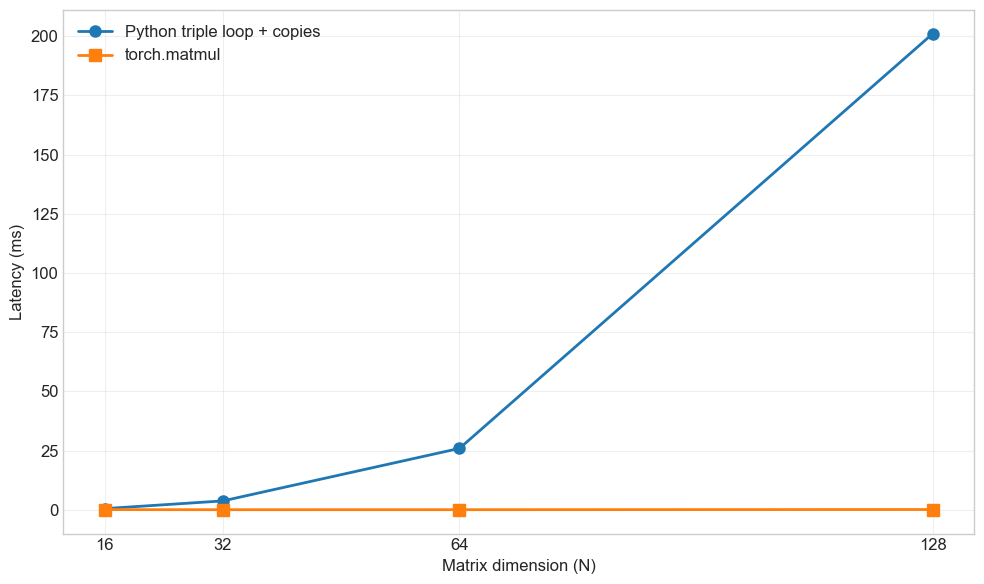

In [7]:
# ===== 【辅助修正】小规模学习配置、相同端到端口径与正确绘图单位 =====
sizes = [16, 32, 64, 128] if LEARNING_MODE else [64, 128, 256, 512]  # 学习模式避免长时间等待纯 Python 大循环。
gemm_latencies = []  # 保存手写版毫秒数。
torch_matmul_latencies = []  # 保存优化版毫秒数。
for size in sizes:  # 每次只改变矩阵边长。
    a = torch.randn(size, size, dtype=torch.float32, device=device)  # 当前左矩阵。
    b = torch.randn(size, size, dtype=torch.float32, device=device)  # 当前右矩阵。
    gemm_latencies.append(latency(gemm, a, b, warmup=1, repeat=3, timer="wall") * 1000)  # CPU 循环及往返拷贝的端到端毫秒数。
    torch_matmul_latencies.append(latency(torch.matmul, a, b, warmup=1, repeat=3, timer="wall") * 1000)  # 相同端到端计时口径。
    del a, b  # 删除本轮输入的引用。
print(pd.DataFrame({"N": sizes, "Python GEMM ms": gemm_latencies, "torch.matmul ms": torch_matmul_latencies}).to_string(index=False))  # 打印真实结果。
ax = plot_gemm_torch_matmul_latency(sizes, gemm_latencies, torch_matmul_latencies)  # 工具函数纵轴使用 ms，传入值也已换算为 ms。
ax.lines[0].set_label("Python triple loop + copies")  # 把工具原先的 tiled 标签改为本题真正实现。
ax.legend()  # 更新图例。
plt.show()  # 显示两种实现的延迟图。


## Part 1.2: MAC & FLOPs

**中文导读：MAC 和 FLOPs 是两种计数口径。**

一次 `累加值 += a * b` 可按 1 次 MAC 计数，也可按“1 次乘法 + 1 次加法”计为 2 FLOPs。对矩阵乘法，本实验采用这个常见换算口径。

注意：计数口径不意味着任意硬件每个时钟周期都恰好完成一次 MAC。FLOPs 表示运算次数，FLOPS 或 TFLOPS 表示每秒运算吞吐率；运算量也不能直接当作延迟。

**Multiply-Accumulate (MAC)** operation is a fundamental building block in digital signal processing and artificial intelligence hardware. It computes the product of two numbers and adds that result to an accumulating sum, effectively performing the operation $a \leftarrow a + (b \times c)$. This single-cycle instruction is critical because it forms the basis of dot products and matrix multiplications, which are the primary mathematical engines behind neural networks.

**FLOPs (Floating Point Operations)** count the total number of individual arithmetic operations involving decimal numbers. These operations include addition, subtraction, multiplication, and division.

Based on the above definitions, you can see that 1 MAC consists of 2 FLOPs (1 for multiplication and 1 for addition).


#### Question 1.3 (5 points)

**中文题意：根据矩阵形状计算 MAC 次数。**

先数结果有多少个元素，再数每个结果元素需要累加多少个乘积。这个函数只需读取输入形状并计算一个整数，不需要真正运行矩阵乘法。下一格的 `assert` 是公开检查案例。

Please calculate the MAC of your matrix multiplication

**【已补全·重点解释】Q1.3：矩阵乘法 MAC**

A[N,K] × B[K,M] 产生 N×M 个输出。每个输出累加 K 个乘积，因此 **MAC=N×M×K**。这里只访问形状，不执行矩阵乘法；常用 FLOPs 估算为 2×MAC。

In [8]:
# ===== 【已补全】Q1.3：矩阵乘法 MAC =====
def gemm_mac(x, y):  # 根据形状统计理论 MAC 次数。
    N, K = x.shape  # 左矩阵是 N 行、K 列。
    K_b, M = y.shape  # 右矩阵是 K_b 行、M 列。
    if K != K_b:  # 内维度必须一致才能进行矩阵乘法。
        raise ValueError("两个矩阵的内维度不一致。")  # 输入不合法时立即报错。
    return N * M * K  # N×M 个输出，每个输出做 K 次乘加。


In [9]:
# 公开检查案例：确认你的函数对这些输入给出预期结果。
A = torch.randn(512, 512, dtype=torch.float32, device=device)  # 创建标准正态随机张量 A，形状为 [512, 512]；dtype=torch.float32 指定数值类型，device=device 指定存放设备。
B = torch.randn(512, 512, dtype=torch.float32, device=device)  # 创建标准正态随机张量 B，形状为 [512, 512]；dtype=torch.float32 指定数值类型，device=device 指定存放设备。
assert gemm_mac(A, B) == 134217728  # 检查方阵案例的 MAC 计算是否符合给定结果；assert 失败会抛出 AssertionError。

A = torch.randn(512, 256, dtype=torch.float32, device=device)  # 创建标准正态随机张量 A，形状为 [512, 256]；dtype=torch.float32 指定数值类型，device=device 指定存放设备。
B = torch.randn(256, 512, dtype=torch.float32, device=device)  # 创建标准正态随机张量 B，形状为 [256, 512]；dtype=torch.float32 指定数值类型，device=device 指定存放设备。
assert gemm_mac(A, B) == 67108864  # 用不同形状再次检查，避免只对某个特定方阵写出了正确结果。

## Part 1.3: I/O

**中文导读：这里的 I/O 主要指显存与计算单元之间的数据搬运。**

一次算子通常要读取输入和权重，并写回输出。理论字节数 = 各次读取/写入的元素数 × 每个元素的字节数。FP32 是 4 字节，FP16/BF16 是 2 字节。

这里不是读取磁盘文件的 I/O，也不等于“程序总共占用了多少显存”。读写量是流量，显存占用是某个时刻保存的数据量。

I/O, which is memory access, consists of the following parts:
- **Read**: Loading weights and input activations from HBM
- **Write**: Storing output activations to HBM
Thus, the I/O cost of one operation is simply the total memory bytes read plus the total memory bytes written.

#### Question 1.4 (5 points)

**中文题意：估算矩阵乘法的理论读写字节数。**

分别数 A、B 的元素数，以及结果 C 的元素数；按本题 FP32 的字节数换算。公开案例采用的是输入各读一次、输出写一次的简化模型，实际硬件流量还会受到缓存、分块和重复读取的影响。

Finish the code below to compute the I/O of the `gemm`.

**【已补全·重点解释】Q1.4：矩阵乘法 I/O**

按本题理想化模型，A 与 B 各读一次，C 写一次：**字节数=(N×K + K×M + N×M)×4**。4 来自 FP32 每个元素 4 字节。这是理论流量，不是峰值显存，也未模拟硬件缓存的具体命中情况。

In [10]:
# ===== 【已补全】Q1.4：矩阵乘法 I/O =====
def gemm_io(A, B):  # 返回本题 FP32 矩阵乘法的理论读写字节数。
    N, K = A.shape  # 取得左输入的形状。
    K_b, M = B.shape  # 取得右输入的形状。
    if K != K_b:  # 检查矩阵乘法的共同维度。
        raise ValueError("两个矩阵的内维度不一致。")  # 防止对无效形状计算结果。
    bytes_per_elem = 4  # 本题固定按 float32，每元素 4 字节。
    return (N * K + K * M + N * M) * bytes_per_elem  # 两个输入读取，加一个输出写回。


In [11]:
# 公开检查案例：确认你的函数对这些输入给出预期结果。
A = torch.randn(512, 512, dtype=torch.float32, device=device)  # 创建标准正态随机张量 A，形状为 [512, 512]；dtype=torch.float32 指定数值类型，device=device 指定存放设备。
B = torch.randn(512, 512, dtype=torch.float32, device=device)  # 创建标准正态随机张量 B，形状为 [512, 512]；dtype=torch.float32 指定数值类型，device=device 指定存放设备。
assert gemm_io(A, B) == 3145728  # 检查第一组输入的理论读写字节数；需要包含输入读取和结果写回。

A = torch.randn(512, 256, dtype=torch.float32, device=device)  # 创建标准正态随机张量 A，形状为 [512, 256]；dtype=torch.float32 指定数值类型，device=device 指定存放设备。
B = torch.randn(256, 512, dtype=torch.float32, device=device)  # 创建标准正态随机张量 B，形状为 [256, 512]；dtype=torch.float32 指定数值类型，device=device 指定存放设备。
assert gemm_io(A, B) == 2097152  # 检查第二组矩形矩阵的 I/O 估算结果。

A = torch.randn(128, 256, dtype=torch.float32, device=device)  # 创建标准正态随机张量 A，形状为 [128, 256]；dtype=torch.float32 指定数值类型，device=device 指定存放设备。
B = torch.randn(256, 512, dtype=torch.float32, device=device)  # 创建标准正态随机张量 B，形状为 [256, 512]；dtype=torch.float32 指定数值类型，device=device 指定存放设备。
assert gemm_io(A, B) == 917504  # 检查第三组形状的 I/O 估算结果，确认通用性。


# Part 2: Roofline Model

**中文导读：Roofline（屋顶线）帮助判断速度受什么限制。**

算术强度 = **总计算 FLOPs ÷ 总读写字节数**，单位是 FLOPs/Byte。这里的 AI 是 Arithmetic Intensity，不是“人工智能”的缩写。分子表示计算量，不是通信量。

横轴是算术强度，纵轴是可达到的计算吞吐率。理论性能上限取两者较小值：`min(显存带宽 × 算术强度, 峰值计算吞吐率)`。左边斜线对应带宽上限，右边水平线对应算力上限，交点称 ridge point（拐点）。

显存容量决定“能否放得下”，带宽与算力决定这个简化模型下“最多有多快”。真实测量点常在屋顶线下方，因为模型未包括所有开销。

When we run algorithms on hardware, we're bounded by three things: how fast our computer can do math (OPs/second), the bandwidth available for moving data around (bytes/second), and the total memory available to store data (bytes). These “roofline” constraints let us upper and lower bound the time of a given computation.

**Arithmetic Intensity:** The arithmetic intensity of an algorithm is given by the ratio of the total FLOPs it performs to the number of bytes it needs to communicate — either within a chip or between chips.

$$ \text{Arithmetic Intensity (AI)} = \frac{\text{Communication FLOPs}}{\text{Communication Bytes}} $$

In Roofline model, we define the ridge point as the arithmetic intensity where the roofline transitions from memory-bound to compute-bound, calculated as $ \frac{\text{peak FLOPs}}{\text{peak memory bandwidth}}$. Different GPU devices have different ridge points.

The roofline has two regions:
- **Memory-bound region** (left of ridge point): Performance = Bandwidth × AI
- **Compute-bound region** (right of ridge point): Performance = Peak FLOPs

<img src="./assets/roofline.png" width=60%>

#### Question 2.1.1 (5 points)

**中文题意：为几种 FP32 方阵规模画屋顶线并标出算术强度。**

组合前面实现的 MAC、I/O 函数，先统一 FLOPs 与字节数的单位，再调用 `plot_roofline`。`gpu_name` 是理论参数字典的键，修改它只改变参考曲线，不会把代码切换到另一块 GPU。

Plot the roofline of matrix-matrix multiplication of the given dimensions. You can use the `plot_roofline` function we provide for you. You can assume all matrices are in `float32`.

**【已补全·重点解释】Q2.1.1：GEMM 屋顶线**

对 N 阶 FP32 方阵，FLOPs≈2N³，I/O≈12N² 字节，所以算术强度为 **N/6 FLOPs/Byte**。随着 N 增大，权重复用带来更高的算术强度。

本格沿用原题的 A6000 理论配置；它是参考硬件模型，和你本机实际使用哪块 GPU 是两回事。这里只计算公式，无需真的分配 8192×8192 张量。图上的点是理论上限位置，不是实测 TFLOPS。

   N  FLOPs/Byte
1024  170.666667
2048  341.333333
4096  682.666667
8192 1365.333333


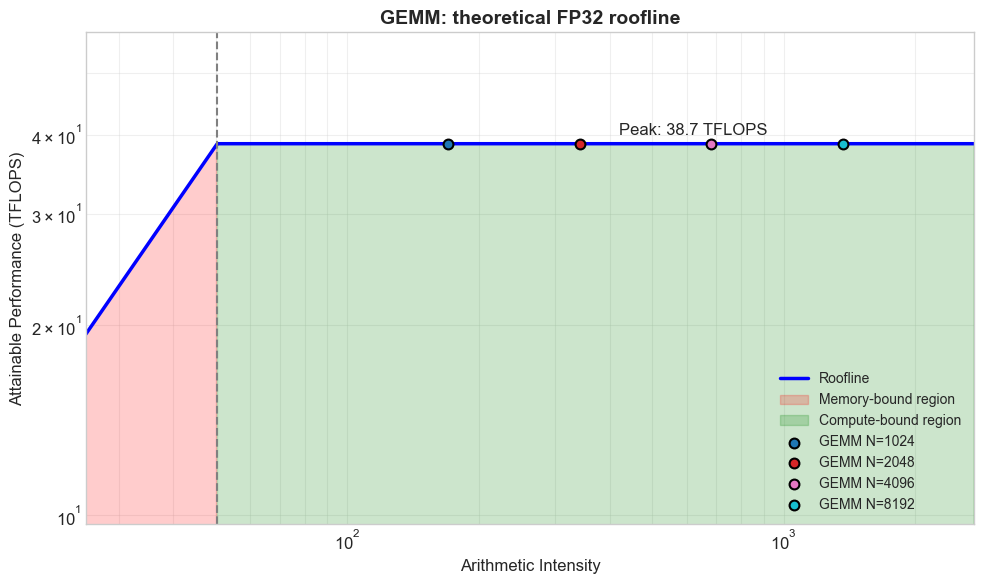

In [12]:
# ===== 【已补全】Q2.1.1：GEMM 屋顶线 =====
Ns = [1024, 2048, 4096, 8192]  # 原题要求比较的方阵边长。
gpu_name = "A6000"  # 保留原题理论参考；修改此名称不会切换实际 GPU。
gpu_spec = GPU_SPECS[gpu_name]  # 从本地字典读取理论规格。
peak_flops = gpu_spec["fp32_tflops"]  # FP32 峰值吞吐率，单位 TFLOPS。
peak_bandwidth = gpu_spec["memory_bandwidth_tb_s"]  # 显存带宽，单位 TB/s。
gemm_ai = {}  # 保存每种规模的算术强度。
for N in Ns:  # 遍历方阵边长，不实际进行大矩阵分配。
    flops = 2 * N * N * N  # N³ 次 MAC，按每 MAC 两个 FLOPs 换算。
    io_bytes = 4 * (N * N + N * N + N * N)  # 读 A、读 B、写 C，各 N² 个 FP32 元素。
    gemm_ai[f"GEMM N={N}"] = flops / io_bytes  # 用 FLOPs 除以字节数。
print(pd.DataFrame({"N": Ns, "FLOPs/Byte": list(gemm_ai.values())}).to_string(index=False))  # 打印可核对数值。
plot_roofline(gpu_name, peak_flops, peak_bandwidth, gemm_ai, title="GEMM: theoretical FP32 roofline")  # 画理论屋顶线。
plt.show()  # 在 notebook 中显示图。


#### Question 2.1.2 (5 points)

**中文题意：推导方阵边长达到什么条件时，理论模型进入算力限制区。**

先把算术强度写成 N 的函数，再与 A6000 对应的拐点比较。写明使用 FP32、每元素字节数和读写次数的假设；这是理论边界，实际利用率还需要测量验证。

How large does N need to be for the gemm to become compute bound on A6000? Provide your derivation. All tensors are in `float32`.

**Your Answer:**

**【已补全·Q2.1.2 推导】**

假设两个输入与输出都是 N×N 的 FP32 矩阵，输入各读一次、输出写一次：

- 计算量：2N³ FLOPs。
- 读写量：4×(N²+N²+N²)=12N² 字节。
- 算术强度：AI(N)=2N³/(12N²)=N/6 FLOPs/Byte。

原题 A6000 配置为 38.7 TFLOPS 和 0.768 TB/s，拐点为 38.7/0.768=50.390625 FLOPs/Byte。因此 `N/6 >= 50.390625`，即 `N >= 302.34375`，整数边长至少为 **303**。

这是该 FP32 理论屋顶线的边界；矩阵分块、Tensor Core 模式、缓存与启动开销会影响实测表现。不能据此声称 N=303 的本机测量一定达到峰值。


#### Question 2.2 (5 points)

**中文题意：把矩阵乘矩阵改为矩阵乘向量，画图并描述区别。**

重点检查第二个输入的形状，以及输出元素数怎样变化；不能只复用方阵公式。比较不同 N 下权重读取量和计算量怎样增长，结合算术强度解释结果。

Now let's plot the roofline of gemv. The settings are the same as above. Describe your findings.

**Your Answer:**

**【已补全·Q2.2 解释】**

GEMV 的计算量为 2N²，读写量为 4(N²+2N)，所以算术强度趋近 **0.5 FLOPs/Byte**。它远小于原题 A6000 的 FP32 拐点 50.39，因此在此模型下处于带宽限制区。

GEMM 中一个矩阵的权重能为多个输出列复用，AI 随 N 增长；单向量 GEMV 中每次读入的权重服务的计算较少，所以只增大 N 很难跨越拐点。下一格给出公式计算出的数值与理论图，不是实测 TFLOPS。


**【已补全·重点解释】Q2.2：GEMV 屋顶线**

N×N 矩阵乘 N×1 向量，FLOPs≈2N²；读取矩阵 N² 个元素、向量 N 个元素，再写 N 个结果，因此 **AI=2N²/[4(N²+2N)]**，N 很大时趋近 0.5 FLOPs/Byte。

矩阵变大时，每个权重仍只服务较少计算，算术强度不会像 GEMM 那样随 N 线性增长。按 A6000 的理论模型，这些点远在拐点左侧。

   N  FLOPs/Byte
1024    0.499025
2048    0.499512
4096    0.499756
8192    0.499878


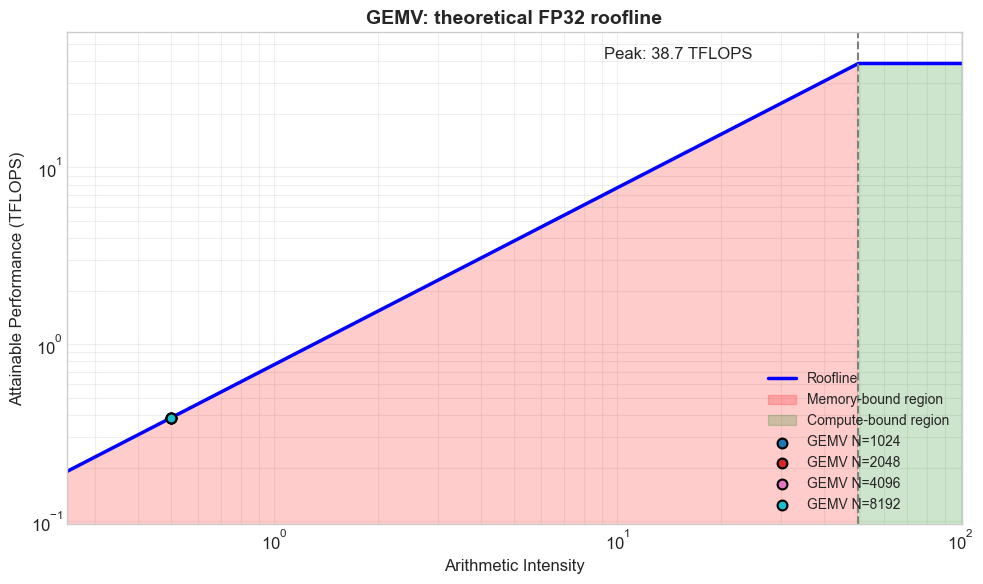

In [13]:
# ===== 【已补全】Q2.2：GEMV 屋顶线 =====
Ns = [1024, 2048, 4096, 8192]  # 与上一题使用相同边长。
gpu_name = "A6000"  # 使用同一理论参考 GPU，确保比较一致。
gpu_spec = GPU_SPECS[gpu_name]  # 读取理论规格。
peak_flops = gpu_spec["fp32_tflops"]  # FP32 理论计算上限。
peak_bandwidth = gpu_spec["memory_bandwidth_tb_s"]  # 理论显存带宽。
gemv_ai = {}  # 保存矩阵乘向量的算术强度。
for N in Ns:  # 对每个规模代入公式。
    flops = 2 * N * N  # N 个输出，每个有 N 次 MAC。
    io_bytes = 4 * (N * N + N + N)  # 读矩阵、读向量、写向量。
    gemv_ai[f"GEMV N={N}"] = flops / io_bytes  # 得到接近 0.5 的 FLOPs/Byte。
print(pd.DataFrame({"N": Ns, "FLOPs/Byte": list(gemv_ai.values())}).to_string(index=False))  # 展示理论值。
plot_roofline(gpu_name, peak_flops, peak_bandwidth, gemv_ai, title="GEMV: theoretical FP32 roofline")  # 放到相同模型中。
plt.show()  # 显示图。


# Part 3: Case Study - Gemma-3 Decoder Layer

**中文导读：先把大段 decoder 代码拆成几个模块。**

| 类或函数 | 作用 | 阅读重点 |
| --- | --- | --- |
| `GELUTanh` | 激活函数 | `partial` 固定参数，`forward` 执行计算 |
| `Gemma3MLP` | 门控前馈网络 | 两条 D→I 投影、激活与逐元素乘法、I→D 投影 |
| `Gemma3RMSNorm` | 调整特征尺度 | 最后一维求均方、取平方根倒数、乘可训练缩放 |
| `rotate_half` / `apply_rotary_pos_emb` | 加入位置信息 | 切片、拼接、广播、Q/K 的位置旋转 |
| `Gemma3Attention` | 注意力模块 | Q/K/V 形状、历史 KV、输出投影 |
| `Gemma3RotaryEmbedding` | 根据位置计算 cos/sin | 新增维度、批量矩阵乘法、设备与类型 |
| `Gemma3DecoderLayer` | 组合完整的一层 | 归一化→注意力→残差→归一化→MLP→残差 |

**Python 阅读提示：** `class X(nn.Module)` 表示继承；`__init__` 定义对象建立时有哪些子模块；`self.xxx` 把内容存到对象中；`forward` 定义前向计算。调用 `module(x)` 会经过 PyTorch 的模块调用流程执行前向。

冒号和 `->` 常用于类型注解，主要帮助阅读与工具检查，并不会自动校验运行时类型；实际返回对象以函数体的 `return` 为准。

这些类描述了计算结构，没有下载预训练权重。下方带 `record_function` 的区域只是给性能分析器加名称标记，不会因此合并内核。

In this section, we will walk you through [gemma-3-270m-it](https://huggingface.co/google/gemma-3-270m-it), a lightweight instruction-tuned language model, as a case study to enhance your profiling knowledge.

All components of the model's one decoder layer are shown below. These components are (in the order of forward execution)
- **Input LayerNorm**
- **Self-Attention Layer**
    - Query and Key Norm
    - Query, Key, and Value Projections
    - Rotary Embedding
    - Output Projection
- **Post Attention LayerNorm**
- **Pre MLP LayerNorm**
- **MLP**
    - Gate Projection
    - Up Projection
    - Activation
    - Down Projection
- **Post MLP LayerNorm**

You don't have to know all details. We will break it down later.

**Note on the MAC / I/O questions:** follow the conventions of the MLP examples below. If you make any additional assumptions (e.g., about which operations to count), please state them in a comment. Any reasonable, clearly stated assumption will receive full credit.

**【辅助修正·重点解释】保证重复解码基准有明确的缓存语义**

缓存改为使用 `StaticCache.update(..., cache_position=...)` 的正式接口，重复测试覆盖固定位置，不让前缀长度随预热次数增长。因果掩码同时屏蔽未来位置和静态缓存尚未写入的槽位。

无缓存路径为完整历史生成各自的位置编码，当前查询只取末尾的编码；历史特征也先经过相同输入归一化。第 3.3 节先显示 BF16/FP16 的整体相对 RMS 误差，再把同一权重和输入转为 FP32 做严格一致性检查。低精度下不同矩阵形状可能选用不同运算顺序，靠近零的单个元素不能只用相对误差判断。小配置只运行一层；大配置仍重复使用同一个层对象模拟计算开销，并非多个独立预训练层。

In [14]:
import math  # 导入数学函数模块，供公式中的数学计算使用。
import functools  # 导入函数工具模块，后面用 partial 预先固定某个函数参数。
import torch  # 导入 PyTorch，后面用 torch 创建张量、执行计算和访问 CUDA。
import torch.nn as nn  # 导入神经网络模块并起别名 nn，后面用 nn.Module、nn.Linear 构造模型。
from transformers.utils import TransformersKwargs  # 从 Transformers 引入额外参数的类型说明；用于注解，不会直接执行模型计算。
from transformers.utils.generic import maybe_autocast  # 引入控制自动混合精度的上下文工具；本实验 utils/config.py 也提供相应兼容处理。
from transformers.processing_utils import Unpack  # 引入用于关键字参数类型展开的注解工具，帮助说明 **kwargs 中可以包含哪些参数。
from transformers.cache_utils import Cache  # 引入 KV 缓存的基础类型，用于函数参数注解。
from transformers.modeling_utils import ALL_ATTENTION_FUNCTIONS  # 引入注意力实现的注册表，后面按配置名查找实际调用的实现。
from transformers.models.gemma3.configuration_gemma3 import Gemma3TextConfig  # 引入 Gemma 3 文本模型配置类，其中保存隐藏维度、头数等超参数。


class GELUTanh(nn.Module):  # 定义 GeLU 激活模块；继承 nn.Module 后，可以作为子模块组合进模型。

    def __init__(self, use_gelu_tanh_python: bool = False):  # 创建对象时执行初始化；bool 和 False 表示布尔参数及默认值，本段实现尚未使用这个开关。
        super().__init__()  # 调用父类 nn.Module 的初始化方法，先建立参数和子模块管理机制。
        self.act = functools.partial(nn.functional.gelu, approximate="tanh")  # 预先固定 gelu 的 approximate 参数，之后调用 self.act(x) 就使用 tanh 近似。

    def forward(self, input):  # 定义激活模块的前向计算；input 是局部参数名，用来接收输入张量。
        return self.act(input)  # 对输入应用固定了参数的 GeLU，输出形状与输入一致。


def rotate_half(x):  # 定义 RoPE 使用的辅助旋转操作，把最后一维拆成两半并重新组合。
    x1 = x[..., : x.shape[-1] // 2]  # ... 保留前面所有维度；沿最后一维取前半部分，// 表示整数除法。
    x2 = x[..., x.shape[-1] // 2 :]  # 沿最后一维取后半部分；切片冒号右侧省略，表示一直取到末尾。
    return torch.cat((-x2, x1), dim=-1)  # 将后半取负、前半保持原值，沿最后一维拼接；dim=-1 表示最后一维。


def apply_rotary_pos_emb(q, k, cos, sin, position_ids=None, unsqueeze_dim=1):  # 定义旋转位置编码；这里直接使用已算出的 cos/sin，position_ids 参数没有在函数体内使用。
    cos = cos.unsqueeze(unsqueeze_dim)  # 在指定位置增加长度为 1 的维度，让 cos 能按广播规则与各注意力头相乘。
    sin = sin.unsqueeze(unsqueeze_dim)  # 为 sin 增加相同的维度，使其与 Q/K 的形状对齐。
    q_embed = (q * cos) + (rotate_half(q) * sin)  # 逐元素组合 Q、旋转后的 Q 与位置角度，得到含位置信息的查询。
    k_embed = (k * cos) + (rotate_half(k) * sin)  # 对 K 应用同样的位置旋转，让查询与键的匹配包含位置信息。
    return q_embed, k_embed  # 用逗号返回两个结果；调用方可用两个变量拆包接收。


class Gemma3MLP(nn.Module):  # 定义门控前馈网络模块，由 gate、up、激活与 down 路径组成。
    def __init__(self, config: Gemma3TextConfig):  # 初始化 MLP；冒号后的类型注解说明 config 预期为模型配置对象。
        super().__init__()  # 调用父类 nn.Module 的初始化方法，先建立参数和子模块管理机制。
        self.config = config  # 把传入的配置保存到当前对象，其他方法可用 self.config 访问。
        self.hidden_size = config.hidden_size  # 读取隐藏维度 D，也就是每个 token 的输入和输出特征数量。
        self.intermediate_size = config.intermediate_size  # 读取 MLP 中间维度 I，通常比隐藏维度大。
        self.gate_proj = nn.Linear(self.hidden_size, self.intermediate_size, bias=False)  # 创建门控投影 D→I；bias=False 表示不额外学习偏置。
        self.up_proj = nn.Linear(self.hidden_size, self.intermediate_size, bias=False)  # 创建另一条独立的 D→I 投影；它与 gate 形状相同，但权重是不同的参数。
        self.down_proj = nn.Linear(self.intermediate_size, self.hidden_size, bias=False)  # 创建 I→D 的输出投影，把扩展的特征映射回原隐藏维度。
        self.act_fn = GELUTanh()  # 创建前面定义的 GeLU 模块，作为门控分支的激活函数。

    def forward(self, x):  # 定义模块的前向计算；self 指当前对象，x 是输入张量。
        with torch.profiler.record_function("gate_proj"):  # 给下面的计算区域标记名称 gate_proj，便于在性能时间线上定位；标记本身不会融合或改变计算。
            gate = self.gate_proj(x)    # 对 [B, L, D] 输入做门控投影，得到 [B, L, I]。
        with torch.profiler.record_function("up_proj"):  # 给下面的计算区域标记名称 up_proj，便于在性能时间线上定位；标记本身不会融合或改变计算。
            up_x = self.up_proj(x)  # 对同一输入执行独立的 up 投影，得到另一份 [B, L, I] 特征。
        with torch.profiler.record_function("act_fn"):  # 给下面的计算区域标记名称 act_fn，便于在性能时间线上定位；标记本身不会融合或改变计算。
            gate_up = self.act_fn(gate) * up_x    # 先对 gate 做 GeLU，再与 up_x 逐元素相乘；这里的 * 不是矩阵乘法。
        with torch.profiler.record_function("down_proj"):  # 给下面的计算区域标记名称 down_proj，便于在性能时间线上定位；标记本身不会融合或改变计算。
            down_proj = self.down_proj(gate_up)    # 把门控后的 [B, L, I] 特征投影回 [B, L, D]。
        return down_proj  # 返回 MLP 输出，批大小、序列长度和隐藏维度都与输入对应。


class Gemma3RMSNorm(nn.Module):  # 定义均方根归一化模块，沿每个 token 的特征维度调整数值尺度。
    def __init__(self, dim: int, eps: float = 1e-6):  # 指定特征维度和数值稳定项；1e-6 表示百万分之一，类型注解不负责强制检查。
        super().__init__()  # 调用父类 nn.Module 的初始化方法，先建立参数和子模块管理机制。
        self.eps = eps  # 保存一个很小的正数，后面加到分母中，避免除零等数值问题。
        self.weight = nn.Parameter(torch.zeros(dim))  # 创建长度为 dim 的可训练参数；nn.Parameter 让 PyTorch 自动注册它。

    def _norm(self, x):  # 定义内部归一化辅助方法；前导下划线表示约定为内部使用，并不是访问权限限制。
        return x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + self.eps)  # 最后一维先平方、求平均、加 eps，再求平方根的倒数；keepdim 保留维度，便于广播乘回 x。

    def forward(self, x):  # 定义模块的前向计算；self 指当前对象，x 是输入张量。
        output = self._norm(x.float())  # 先把输入转成 float32 做归一化，降低低精度运算的数值误差。
        output = output * (1.0 + self.weight.float())  # 用可训练缩放因子调整输出；这里参数从 0 开始，实际初始缩放是 1。
        return output.type_as(x)  # 把结果转换回与原始输入 x 相同的张量类型，再返回。

    def extra_repr(self):  # 定义打印模型结构时额外显示的文字，不参与前向数值计算。
        return f"{tuple(self.weight.shape)}, eps={self.eps}"  # 返回包含参数形状和 eps 的说明文字，f 字符串会替换花括号中的表达式。


class Gemma3Attention(nn.Module):  # 定义注意力模块，包含 Q/K/V 投影、位置编码、注意力核心和输出投影。

    def __init__(self, config: Gemma3TextConfig, layer_idx: int):  # 初始化当前层；layer_idx 是层编号，用来读取层类型和访问对应缓存。
        super().__init__()  # 调用父类 nn.Module 的初始化方法，先建立参数和子模块管理机制。
        self.layer_type = config.layer_types[layer_idx] if hasattr(config, "layer_types") else None  # 条件表达式：配置有 layer_types 属性时取本层类型，否则记为 None。
        self.config = config  # 把传入的配置保存到当前对象，其他方法可用 self.config 访问。
        self.layer_idx = layer_idx  # 保存本层编号，后面用它定位缓存中的这一层。
        self.head_dim = getattr(config, "head_dim", config.hidden_size // config.num_attention_heads)  # 优先读取配置的每头维度；未提供该属性时，才采用隐藏维度除以查询头数的默认值。
        self.num_key_value_groups = config.num_attention_heads // config.num_key_value_heads  # 计算每组共享 K/V 的查询头数量；查询头数和 KV 头数可以不同。
        self.scaling = config.query_pre_attn_scalar**-0.5  # ** 表示幂，-0.5 表示平方根的倒数，用于缩放注意力分数。
        self.attention_dropout = self.config.attention_dropout  # 保存注意力 dropout 概率，前向计算时还会根据训练状态选择是否使用。
        self.is_causal = True  # 标记为因果注意力模块，具体掩码行为还由被调用的注意力实现及传入掩码决定。

        self.q_proj = nn.Linear(  # 开始创建 Q 投影层，把隐藏特征映射到所有查询头的特征。
            config.hidden_size, config.num_attention_heads * self.head_dim, bias=config.attention_bias  # 输入为隐藏维度，输出为查询头数×每头维度，是否带偏置由配置决定。
        )  # 结束上方跨行书写的调用或容器；括号内换行不代表开始了新的独立语句。
        self.k_proj = nn.Linear(  # 开始创建 K 投影层，用于生成参与匹配的键向量。
            config.hidden_size, config.num_key_value_heads * self.head_dim, bias=config.attention_bias  # K/V 投影使用 KV 头数计算输出维度，因此可能小于 Q 的投影维度。
        )  # 结束上方跨行书写的调用或容器；括号内换行不代表开始了新的独立语句。
        self.v_proj = nn.Linear(  # 开始创建 V 投影层，用于生成加权汇总的值向量。
            config.hidden_size, config.num_key_value_heads * self.head_dim, bias=config.attention_bias  # K/V 投影使用 KV 头数计算输出维度，因此可能小于 Q 的投影维度。
        )  # 结束上方跨行书写的调用或容器；括号内换行不代表开始了新的独立语句。
        self.o_proj = nn.Linear(  # 开始创建输出投影层，将多个注意力头的结果映射回隐藏维度。
            config.num_attention_heads * self.head_dim, config.hidden_size, bias=config.attention_bias  # 输入为全部查询头拼接后的维度，输出回到模型隐藏维度。
        )  # 结束上方跨行书写的调用或容器；括号内换行不代表开始了新的独立语句。
        self.attn_logit_softcapping = None  # 此实验未设置注意力分数的 softcapping 参数。
        self.sliding_window = None  # 此实验未指定局部滑动窗口大小，当前模块按相应实现处理完整范围。
        self.is_sliding = False  # 将本模块标记为非滑动窗口注意力。

        self.q_norm = Gemma3RMSNorm(dim=config.head_dim, eps=config.rms_norm_eps)  # 创建 Q 的逐头归一化模块，作用维度是每头特征维度。
        self.k_norm = Gemma3RMSNorm(dim=config.head_dim, eps=config.rms_norm_eps)  # 为 K 创建独立的归一化模块及参数。

    # ===== 【辅助修正】固定缓存位置，支持重复基准测量与正确的历史位置编码 =====
    def forward(self, hidden_states, position_embeddings=None, attention_mask=None,  # 输入特征、位置编码和可选掩码。
                use_kv_cache=True, past_key_values=None, cache_position=None,  # 缓存开关、缓存对象和固定写入位置。
                prefill_hidden_states=None, **kwargs):  # 保留原调用参数，返回一个输出张量。
        B, L_q, _ = hidden_states.shape  # 输入为批次、查询长度、隐藏维度。
        query_states = self.q_proj(hidden_states).view(B, L_q, -1, self.head_dim).transpose(1, 2)  # 生成 [B,Hq,Lq,Dh]。
        query_states = self.q_norm(query_states)  # 对查询的每个头做归一化。
        key_inputs = hidden_states  # 默认只为当前 token 生成新的 K/V。
        if not use_kv_cache and prefill_hidden_states is not None:  # 无缓存解码需要重新处理历史特征。
            key_inputs = torch.cat((prefill_hidden_states, hidden_states), dim=1)  # 合并历史与新 token。
        L_k = key_inputs.shape[1]  # 当前要投影的键/值 token 数。
        key_states = self.k_proj(key_inputs).view(B, L_k, -1, self.head_dim).transpose(1, 2)  # 生成真实 KV 头数的键。
        value_states = self.v_proj(key_inputs).view(B, L_k, -1, self.head_dim).transpose(1, 2)  # 生成对应的值。
        key_states = self.k_norm(key_states)  # 对键做逐头归一化。
        cos, sin = position_embeddings  # 带缓存时是当前位置，无缓存时需提供完整历史位置编码。
        q_cos, q_sin = cos[..., -L_q:, :].unsqueeze(1), sin[..., -L_q:, :].unsqueeze(1)  # 查询只使用最后 Lq 个位置。
        k_cos, k_sin = cos.unsqueeze(1), sin.unsqueeze(1)  # 键使用本次投影序列的完整位置编码。
        query_states = query_states * q_cos + rotate_half(query_states) * q_sin  # 对当前 Q 应用 RoPE。
        key_states = key_states * k_cos + rotate_half(key_states) * k_sin  # 对 K 应用它们各自的位置编码。
        if use_kv_cache:  # 历史 K/V 由缓存对象持有。
            if past_key_values is None:  # 缓存路径必须有实际缓存。
                raise ValueError("启用 KV cache 时必须提供 past_key_values。")  # 提示调用方准备缓存。
            if cache_position is None:  # 本地 decode 工具使用复数 cache_positions，兼容这一参数名。
                cache_position = kwargs.pop("cache_positions", None)  # 取出额外关键字，避免继续错误转发。
            if cache_position is None:  # prefill 没有显式传入时，按从 0 开始的位置处理。
                cache_position = torch.arange(L_q, device=hidden_states.device)  # 每个查询对应一个缓存位置。
            key_states, value_states = past_key_values.update(  # 使用缓存的正式接口按固定位置更新，不反复追加同一前缀。
                key_states, value_states, self.layer_idx, {"cache_position": cache_position})  # StaticCache 可以复用已有存储。
            query_positions = cache_position  # 因果掩码需要查询在完整序列中的实际位置。
        else:  # 无缓存路径中的键已经是完整历史加当前输入。
            query_positions = torch.arange(L_k - L_q, L_k, device=hidden_states.device)  # 查询对应完整序列末尾的位置。
        key_positions = torch.arange(key_states.shape[-2], device=hidden_states.device)  # 包含静态缓存可能预留的末尾槽位。
        allowed = key_positions[None, :] <= query_positions[:, None]  # 只允许访问当前查询以前及自身的位置。
        causal_bias = torch.zeros(allowed.shape, device=hidden_states.device, dtype=query_states.dtype)  # 创建加性偏置。
        causal_bias = causal_bias.masked_fill(~allowed, float("-inf"))[None, None, :, :]  # 同时屏蔽未来位置和未写入的槽位。
        if attention_mask is not None:  # 若调用方还提供了其他掩码，一并应用。
            if attention_mask.dtype == torch.bool:  # 布尔 True 表示允许访问。
                causal_bias = causal_bias.masked_fill(~attention_mask, float("-inf"))  # 额外禁止的位置设负无穷。
            else:  # 浮点掩码作为额外偏置。
                causal_bias = causal_bias + attention_mask  # 按兼容形状广播相加。
        attention_interface = ALL_ATTENTION_FUNCTIONS[self.config._attn_implementation]  # 仍使用原配置选择注意力后端。
        with torch.profiler.record_function("attn_op"):  # 为实际注意力计算增加时间线标签。
            attn_output, _ = attention_interface(  # Transformers 接口返回输出及可选权重。
                self, query_states, key_states, value_states, causal_bias,  # 传入模块信息、Q/K/V和显式因果偏置。
                dropout=self.attention_dropout if self.training else 0.0, scaling=self.scaling, **kwargs)  # 明确提供因果偏置。
        attn_output = attn_output.reshape(B, L_q, -1).contiguous()  # 合并所有查询头，恢复 token 布局。
        return self.o_proj(attn_output)  # 输出投影回隐藏维度。


class Gemma3RotaryEmbedding(nn.Module):  # 定义旋转位置编码模块，根据位置编号产生 cos/sin。
    inv_freq: torch.Tensor  # 声明一个张量属性的类型；这行本身没有创建张量或给属性赋值。

    def __init__(self, config, device=None, layer_type=None):  # 初始化位置编码模块，接收配置、可选设备和层类型。
        super().__init__()  # 调用父类 nn.Module 的初始化方法，先建立参数和子模块管理机制。
        self.max_seq_len_cached = config.max_position_embeddings  # 保存配置允许的最大位置长度。
        self.original_max_seq_len = config.max_position_embeddings  # 另存初始最大长度，便于保持原始配置记录。

        self.config = config  # 把传入的配置保存到当前对象，其他方法可用 self.config 访问。
        self.rope_type = {}  # 创建空字典，用于按层类型保存 RoPE 类型。
        rope_params = self.config.rope_parameters[layer_type]  # 按层类型读取对应的 RoPE 参数字典。
        self.rope_type[layer_type] = rope_params["rope_type"]  # 把本层类型对应的 RoPE 方案保存到对象中。
        rope_init_fn = self.compute_default_rope_parameters  # 把方法对象保存到变量中；没有括号，所以这里只取方法，不执行它。
        curr_inv_freq, curr_attention_scaling = rope_init_fn(self.config, device, layer_type=layer_type)  # 调用初始化函数，取得逆频率向量和缩放系数两个返回值。
        self.register_buffer(f"{layer_type}_inv_freq", curr_inv_freq, persistent=False)  # 注册不需要梯度的缓冲张量；会随模块移动设备，persistent=False 表示不写入 state_dict。
        setattr(self, f"{layer_type}_original_inv_freq", curr_inv_freq)  # 用动态生成的属性名保存原始逆频率；setattr 相当于按名字执行对象属性赋值。
        setattr(self, f"{layer_type}_attention_scaling", curr_attention_scaling)  # 用层类型拼出属性名，并保存位置编码的缩放系数。

    @staticmethod  # 装饰器：把下面的方法标记为静态方法，调用时不会自动传入 self。
    def compute_default_rope_parameters(  # 开始定义根据配置计算 RoPE 逆频率的静态方法。
        config: Optional[Gemma3TextConfig] = None,  # 接收模型配置；虽然默认值是 None，当前函数体仍需要实际配置才能取属性。
        device: Optional["torch.device"] = None,  # 接收可选设备；引号中的类型名用于注解，不是在创建设备对象。
        seq_len: Optional[int] = None,  # 接收可选长度参数；当前这份默认 RoPE 实现没有在函数体内使用它。
        layer_type: Optional[str] = None,  # 指定用哪一种层类型的 RoPE 参数。
    ) -> tuple["torch.Tensor", float]:  # 声明返回一个张量和一个浮点数；箭头右侧只说明类型，不执行计算。
        base = config.rope_parameters[layer_type]["rope_theta"]  # 从嵌套字典中读取频率基数，控制不同特征维度的位置变化尺度。
        dim = getattr(config, "head_dim", None) or config.hidden_size // config.num_attention_heads  # 优先取 head_dim；如果不存在或为假值，再计算隐藏维度除以头数。

        attention_factor = 1.0  # 设置默认位置编码缩放因子为 1，即不额外放大或缩小。
        inv_freq = 1.0 / (  # 开始计算各特征维度对应的逆频率；下面的表达式作为分母。
            base ** (torch.arange(0, dim, 2, dtype=torch.int64).to(device=device, dtype=torch.float) / dim)  # 生成 0、2、4 等偶数维编号，转为浮点并除以 dim，再计算基数的相应幂。
        )  # 结束上方跨行书写的调用或容器；括号内换行不代表开始了新的独立语句。
        return inv_freq, attention_factor  # 同时返回逆频率张量和缩放系数。

    @torch.no_grad()  # 装饰器：下面整个方法关闭梯度记录，位置编码准备不需要在这里构建反向传播图。
    def forward(self, x, position_ids, layer_type=None):  # 根据输入张量的设备、类型与位置编号生成本次需要的 cos/sin。
        inv_freq = getattr(self, f"{layer_type}_inv_freq")  # 用动态属性名取出之前注册的逆频率张量。
        attention_scaling = getattr(self, f"{layer_type}_attention_scaling")  # 读取对应层类型的位置编码缩放因子。

        inv_freq_expanded = inv_freq[None, :, None].float().expand(position_ids.shape[0], -1, 1).to(x.device)  # None 索引增加维度，expand 扩展批次维且通常不复制数据，最后移到输入设备。
        position_ids_expanded = position_ids[:, None, :].float()  # 在中间增加一维，将位置编号整理为 [B, 1, L] 并转成浮点数。

        device_type = x.device.type if isinstance(x.device.type, str) and x.device.type != "mps" else "cpu"  # 按输入设备选择混合精度上下文的设备类型；特殊情况使用 cpu。
        with maybe_autocast(device_type=device_type, enabled=False):  # 在该区域禁用自动混合精度，让后面的 float32 位置计算保持预期精度。
            freqs = (inv_freq_expanded.float() @ position_ids_expanded.float()).transpose(1, 2)  # @ 表示批量矩阵乘法，计算每个位置与频率的乘积，再换轴得到 [B, L, D_h/2]。
            emb = torch.cat((freqs, freqs), dim=-1)  # 沿最后一维拼接两份相同频率，形成与每头维度匹配的角度张量。
            cos = emb.cos() * attention_scaling  # 对角度逐元素求余弦，并乘上缩放因子。
            sin = emb.sin() * attention_scaling  # 对相同角度逐元素求正弦，并乘上缩放因子。

        return cos.to(dtype=x.dtype), sin.to(dtype=x.dtype)  # 将 cos/sin 转回与输入相同的数据类型，并作为两个结果返回。


class Gemma3DecoderLayer(nn.Module):  # 定义一个 decoder 层，将注意力、MLP、归一化和残差连接组合起来。
    def __init__(self, config: Gemma3TextConfig, layer_idx: int):  # 初始化当前层；layer_idx 是层编号，用来读取层类型和访问对应缓存。
        super().__init__()  # 调用父类 nn.Module 的初始化方法，先建立参数和子模块管理机制。
        self.config = config  # 把传入的配置保存到当前对象，其他方法可用 self.config 访问。
        self.hidden_size = config.hidden_size  # 读取隐藏维度 D，也就是每个 token 的输入和输出特征数量。
        self.layer_idx = layer_idx  # 保存本层编号，后面用它定位缓存中的这一层。
        self.attention_type = "full_attention"  # 为当前 decoder 层记录全注意力类型。
        self.self_attn = Gemma3Attention(config=config, layer_idx=layer_idx)  # 创建本层的注意力子模块，并传入相同的配置与层编号。
        self.mlp = Gemma3MLP(config)  # 创建本层的门控前馈子模块。
        self.input_layernorm = Gemma3RMSNorm(self.hidden_size, eps=config.rms_norm_eps)  # 创建进入注意力之前的 RMSNorm；属性名虽然含 layernorm，实际类是 RMSNorm。
        self.post_attention_layernorm = Gemma3RMSNorm(self.hidden_size, eps=config.rms_norm_eps)  # 创建注意力输出之后使用的 RMSNorm。
        self.pre_feedforward_layernorm = Gemma3RMSNorm(self.hidden_size, eps=config.rms_norm_eps)  # 创建进入 MLP 之前的 RMSNorm。
        self.post_feedforward_layernorm = Gemma3RMSNorm(self.hidden_size, eps=config.rms_norm_eps)  # 创建 MLP 输出之后的 RMSNorm。

    def forward(  # 开始多行定义 forward，下面列出调用模型时可传入的参数。
        self,  # 当前模块对象 self；方法定义中由模块调用流程传入，调用底层注意力接口时则在这里显式传入。
        hidden_states: torch.Tensor,  # 接收隐藏特征张量，通常形状为 [B, L_q, D]；冒号后面是类型注解。
        position_embeddings: torch.Tensor = None,  # 接收位置编码；当前实现实际拆包使用 cos/sin 两个张量，注解不会强制限制运行时类型。
        attention_mask: Optional[torch.Tensor] = None,  # 可选的注意力掩码；None 表示未显式提供掩码。
        position_ids: Optional[torch.LongTensor] = None,  # 接收可选的 token 位置编号，用关键字参数转交给注意力模块。
        past_key_values: Optional[Cache] = None,  # 接收历史 KV 缓存对象；启用缓存的分支会检查它不能为 None。
        cache_position: Optional[torch.LongTensor] = None,  # 接收 token 在缓存中的位置编号，类型注解说明预期为整数张量。
        **kwargs: Unpack[TransformersKwargs],  # 把未单独列出的关键字参数收集为字典，后面可用 **kwargs 继续转发。
    ) -> torch.Tensor:  # 【辅助修正】当前实现实际返回一个隐藏特征张量。
        residual = hidden_states  # 保留当前特征的引用，稍后用于残差相加；这行没有执行深拷贝。

        with torch.profiler.record_function("input_norm"):  # 给下面的计算区域标记名称 input_norm，便于在性能时间线上定位；标记本身不会融合或改变计算。
            hidden_states = self.input_layernorm(hidden_states)  # 对输入特征归一化，保持 [B, L, D] 的形状。

        # 【辅助修正】无缓存时历史输入也应经过同一输入归一化，再重新投影 K/V。
        if kwargs.get("prefill_hidden_states") is not None:  # 历史原始特征通过额外参数传入。
            kwargs["prefill_hidden_states"] = self.input_layernorm(kwargs["prefill_hidden_states"])  # 与缓存中的前缀使用相同归一化。
        with torch.profiler.record_function("self_attn"):  # 给下面的计算区域标记名称 self_attn，便于在性能时间线上定位；标记本身不会融合或改变计算。
            hidden_states = self.self_attn(  # 开始执行自注意力子模块，下面显式列出传入参数。
                hidden_states=hidden_states,  # 将当前隐藏特征作为命名参数传入子模块。
                position_embeddings=position_embeddings,  # 转交已经算好的 cos/sin 位置编码。
                attention_mask=attention_mask,  # 转交注意力掩码。
                position_ids=position_ids,  # 转交 token 的位置编号。
                past_key_values=past_key_values,  # 传入前面建立的历史 KV 缓存对象。
                cache_position=cache_position,  # 转交本次计算对应的缓存位置。
                **kwargs,  # 把额外关键字参数字典展开，继续传给下层函数。
            )  # 结束上方跨行书写的调用或容器；括号内换行不代表开始了新的独立语句。
        
        with torch.profiler.record_function("post_attn_norm"):  # 给下面的计算区域标记名称 post_attn_norm，便于在性能时间线上定位；标记本身不会融合或改变计算。
            hidden_states = self.post_attention_layernorm(hidden_states)  # 对注意力输出归一化。
        with torch.profiler.record_function("res"):  # 给下面的计算区域标记名称 res，便于在性能时间线上定位；标记本身不会融合或改变计算。
            hidden_states = residual + hidden_states  # 将子模块输出与之前保存的输入相加，形成残差连接，形状保持不变。

        residual = hidden_states  # 保留当前特征的引用，稍后用于残差相加；这行没有执行深拷贝。

        with torch.profiler.record_function("pre_ffn_norm"):  # 给下面的计算区域标记名称 pre_ffn_norm，便于在性能时间线上定位；标记本身不会融合或改变计算。
            hidden_states = self.pre_feedforward_layernorm(hidden_states)  # 对进入前馈网络的特征做归一化。
        with torch.profiler.record_function("mlp"):  # 给下面的计算区域标记名称 mlp，便于在性能时间线上定位；标记本身不会融合或改变计算。
            hidden_states = self.mlp(hidden_states)    # 执行门控 MLP，输出仍为 [B, L, D]。
        with torch.profiler.record_function("post_ffn_norm"):  # 给下面的计算区域标记名称 post_ffn_norm，便于在性能时间线上定位；标记本身不会融合或改变计算。
            hidden_states = self.post_feedforward_layernorm(hidden_states)  # 对 MLP 输出做归一化，然后准备与残差相加。
        with torch.profiler.record_function("res"):  # 给下面的计算区域标记名称 res，便于在性能时间线上定位；标记本身不会融合或改变计算。
            hidden_states = residual + hidden_states  # 将子模块输出与之前保存的输入相加，形成残差连接，形状保持不变。

        return hidden_states  # 返回当前 decoder 层的隐藏特征，供后续层或性能测试使用。

**中文导读：先从独立 MLP 算起。**

下一格重新定义简化版的 `GELUTanh` 和 `Gemma3MLP`，去掉了前面用于性能分析的区域标记。Jupyter 中同名类会被新定义覆盖，之后创建的新对象使用新的类；先前已创建的对象不会自动重建。

## Part 3.1: MAC & FLOPs

In [15]:
class GELUTanh(nn.Module):  # 定义 GeLU 激活模块；继承 nn.Module 后，可以作为子模块组合进模型。
    def __init__(self, use_gelu_tanh_python: bool = False):  # 创建对象时执行初始化；bool 和 False 表示布尔参数及默认值，本段实现尚未使用这个开关。
        super().__init__()  # 调用父类 nn.Module 的初始化方法，先建立参数和子模块管理机制。
        self.act = functools.partial(nn.functional.gelu, approximate="tanh")  # 预先固定 gelu 的 approximate 参数，之后调用 self.act(x) 就使用 tanh 近似。

    def forward(self, input):  # 定义激活模块的前向计算；input 是局部参数名，用来接收输入张量。
        return self.act(input)  # 对输入应用固定了参数的 GeLU，输出形状与输入一致。

class Gemma3MLP(nn.Module):  # 定义门控前馈网络模块，由 gate、up、激活与 down 路径组成。
    def __init__(self, config: Gemma3TextConfig):  # 初始化 MLP；冒号后的类型注解说明 config 预期为模型配置对象。
        super().__init__()  # 调用父类 nn.Module 的初始化方法，先建立参数和子模块管理机制。
        self.config = config  # 把传入的配置保存到当前对象，其他方法可用 self.config 访问。
        self.hidden_size = config.hidden_size  # 读取隐藏维度 D，也就是每个 token 的输入和输出特征数量。
        self.intermediate_size = config.intermediate_size  # 读取 MLP 中间维度 I，通常比隐藏维度大。
        self.gate_proj = nn.Linear(self.hidden_size, self.intermediate_size, bias=False)  # 创建门控投影 D→I；bias=False 表示不额外学习偏置。
        self.up_proj = nn.Linear(self.hidden_size, self.intermediate_size, bias=False)  # 创建另一条独立的 D→I 投影；它与 gate 形状相同，但权重是不同的参数。
        self.down_proj = nn.Linear(self.intermediate_size, self.hidden_size, bias=False)  # 创建 I→D 的输出投影，把扩展的特征映射回原隐藏维度。
        self.act_fn = GELUTanh()  # 创建前面定义的 GeLU 模块，作为门控分支的激活函数。

    def forward(self, x):  # 定义模块的前向计算；self 指当前对象，x 是输入张量。
        gate = self.gate_proj(x)    # 对 [B, L, D] 输入做门控投影，得到 [B, L, I]。
        up_x = self.up_proj(x)  # 对同一输入执行独立的 up 投影，得到另一份 [B, L, I] 特征。
        gate_up = self.act_fn(gate) * up_x    # 先对 gate 做 GeLU，再与 up_x 逐元素相乘；这里的 * 不是矩阵乘法。
        down_proj = self.down_proj(gate_up)    # 把门控后的 [B, L, I] 特征投影回 [B, L, D]。
        return down_proj  # 返回 MLP 输出，批大小、序列长度和隐藏维度都与输入对应。

**中文导读：跟踪 MLP 的形状变化。**

输入 `[B, L, D]` 分成 gate 和 up 两路，各变为 `[B, L, I]`；gate 先经过 GeLU，再与 up 逐元素相乘；最后 down 投影回 `[B, L, D]`。

线性投影可以按矩阵乘法统计 MAC。激活与逐元素乘法仍消耗计算，但本实验不把它们计入 MAC，而在 FLOPs 中单独估算。GeLU 每元素 8 FLOPs 是本课程的简化计数约定，不能理解为底层必定执行 8 条指令。

In this section, we will walk through the MAC & FLOPs computation of the MLP in the decoder layer. The MLP takes in a tensor `x` of shape `(B, L, D)` and outputs a tensor of the same shape. Based on the code below, we can break down the operations as follows:
- `gate_proj`: This is a linear layer with weight $W \in \mathbb{R}^{I \times D}$, so
    - MAC = $B \times L \times D \times I$
    - FLOPs = $2 \times B \times L \times D \times I$
- `up_proj`: This is a linear layer with weight $W \in \mathbb{R}^{I \times D}$, so
    - MAC = $B \times L \times D \times I$
    - FLOPs = $2 \times B \times L \times D \times I$
- `act_fn`: The input is a tensor with shape `(B, L, I)`. Each element goes through 8 operations (6 mul, 2 add, and note that we consider non-fused GeLU here which will be discussed later). So, the
    - MAC is not measurable (numerically 0) because a GeLU unit can't be simplified into a single clock-cycle MAC.
    - FLOPs = $8 \times B \times L \times I$
- `gate_up`: This is an element-wise multiplication of two matrices of shape `(B, L, I)`, so
    - MAC is also not applicable in this case (numerically 0) since there's no "add"
    - FLOPs = $B \times L \times I$
- `down_proj`: This is a linear layer with weight $W \in \mathbb{R}^{D \times I}$, so 
    - MAC = $B \times L \times I \times D$
    - FLOPs = $2 \times B \times L \times I \times D$

In [16]:
def calc_mlp_mac(B, L, D, I):  # 估算 MLP 三个线性层的乘加次数；B 是批大小，L 是序列长度，D 是隐藏维度，I 是中间维度。
    """
    Args:
        B (int): Batch size.
        L (int): Sequence length.
        D (int): Hidden dimension.
        I (int): Intermediate (FFN) dimension.
    Returns:
        int: Total MACs for the MLP block (gate, up, down projections).
    """
    gate_proj = B * L * D * I  # gate 线性投影：B×L 个输入向量，每个从 D 维映射到 I 维。
    up_proj = B * L * D * I  # up 线性投影的输入输出维度与 gate 一致，因此 MAC 次数相同。
    act_fn = 0  # 按本实验口径，激活函数不计入 MAC；数值为 0 不代表它没有运算或没有耗时。
    gate_up = 0  # 按本实验口径，逐元素相乘没有累加步骤，因此不计入 MAC。
    down_proj = B * L * I * D  # down 线性投影把 I 维映射回 D 维，统计相应的乘加次数。
    return gate_proj + up_proj + act_fn + gate_up + down_proj  # 把各阶段在当前函数中统计的运算量相加并返回。

def calc_mlp_flops(B, L, D, I):  # 估算 MLP 的 FLOPs，包含矩阵乘法与本实验约定的逐元素运算。
    """
    Args:
        B (int): Batch size.
        L (int): Sequence length.
        D (int): Hidden dimension.
        I (int): Intermediate (FFN) dimension.
    Returns:
        int: Total floating-point operations for the full MLP path.
    """
    gate_proj = 2 * B * L * D * I  # 每个 MAC 按 2 个 FLOPs 统计：一次乘法、一次加法。
    up_proj = 2 * B * L * D * I  # 对 up 投影使用相同的 FLOPs 统计口径。
    act_fn = 8 * B * L * I  # 按课程的简化模型，每个 GeLU 元素计 8 个 FLOPs，不是逐条硬件指令计数。
    gate_up = B * L * I  # 两个 [B, L, I] 张量逐元素相乘，每个元素计一次乘法。
    down_proj = 2 * B * L * I * D  # down 投影的 MAC 次数乘 2，换算为 FLOPs。
    return gate_proj + up_proj + act_fn + gate_up + down_proj  # 把各阶段在当前函数中统计的运算量相加并返回。

#### Question 3.1 (10 points)

**中文题意：实现缩放点积注意力，再统计它的 MAC。**

先画形状流向：Q 与转置后的 K 相乘得到 `[B, H, L_q, L_kv]` 的匹配分数；缩放并沿键的维度做 softmax；最后与 V 相乘，得到 `[B, H, L_q, D_h]`。

`transpose(-2, -1)` 只交换最后两维，前面的批次和头维度保留。softmax 把每个查询对应的一行分数变成权重。若实现可选掩码，要分清布尔掩码和加性掩码的约定；内置 SDPA 的布尔 True 表示允许参与注意力。

下一格已补全注意力实现与 MAC 统计，并保留后面的原题公开检查。

(1) Please implement the standard scale-dot-product attention from scratch. You can assume all tensors are in `float32`. (2) Then, calculate its MAC. The shape of q is `(B, H, L_q, D)` and the shape of k,v is `(B, H, L_kv, D)`.

**【已补全·重点解释】Q3.1：手写注意力与 MAC**

计算分三步：① Q[B,H,Lq,Dh] × K 转置得到分数 [B,H,Lq,Lkv]；② 除以 √Dh 后，沿最后一维对每个查询的键分数做 softmax；③ 权重乘 V，回到 [B,H,Lq,Dh]。

`transpose(-2,-1)` 只交换最后两维；`@` 是矩阵乘法，`*` 是逐元素乘法。布尔 mask 的 True 表示允许访问，False 位置在 softmax 前设为负无穷；浮点 mask 则作为加性偏置。全屏蔽行原本会产生 NaN，这里将其权重设为零。

QK 与权重乘 V 各有 **B×H×Lq×Lkv×Dh** 次 MAC，所以总 MAC 是两者之和。softmax 与缩放不计入本题的 MAC，但仍有实际计算和访存。

In [17]:
# ===== 【已补全】Q3.1：手写注意力与 MAC =====
def scaled_dot_product_attention(q, k, v, attn_mask=None):  # 接收标准 [B,H,L,Dh] 布局的 Q/K/V。
    scale = q.shape[-1] ** -0.5  # Python ** 是幂；-0.5 相当于 1/√Dh。
    scores = (q @ k.transpose(-2, -1)) * scale  # 计算并缩放每个查询与每个键的匹配分数。
    if attn_mask is not None:  # 仅在提供掩码时处理它。
        if attn_mask.dtype == torch.bool:  # 布尔掩码遵循内置 SDPA 的 True=允许约定。
            scores = scores.masked_fill(~attn_mask, float("-inf"))  # ~ 对布尔值取反，将禁止位置置为负无穷。
        else:  # 浮点掩码表示直接加到分数上的偏置。
            scores = scores + attn_mask  # 利用广播让兼容形状的掩码作用到各批次和头。
    weights = torch.softmax(scores, dim=-1)  # 每个查询沿键的维度归一化，得到注意力权重。
    weights = torch.nan_to_num(weights, nan=0.0)  # 对全部被屏蔽的行返回零权重，避免 NaN 扩散。
    return weights @ v  # 将各位置的 V 按权重汇总，输出 [B,H,Lq,Dh]。

def calc_attn_mac(B, H, L_q, L_kv, D_h):  # 只统计两次矩阵乘法的乘加次数。
    qk = B * H * L_q * L_kv * D_h  # QK 转置乘法：每个分数累加 D_h 个乘积。
    softmax = 0  # 本题将 softmax 排除在 MAC 口径之外，不代表它不耗时。
    attn_v = B * H * L_q * D_h * L_kv  # 输出的每个特征累加 L_kv 个加权值。
    return qk + softmax + attn_v  # 返回总 MAC 次数。


In [18]:
# 注意力输出的公开检查案例。
q = torch.randn(1, 4, 1024, 128, dtype=torch.float32, device=device)  # 创建标准正态随机张量 q，形状为 [1, 4, 1024, 128]；dtype=torch.float32 指定数值类型，device=device 指定存放设备。
k = torch.randn(1, 4, 1024, 128, dtype=torch.float32, device=device)  # 创建标准正态随机张量 k，形状为 [1, 4, 1024, 128]；dtype=torch.float32 指定数值类型，device=device 指定存放设备。
v = torch.randn(1, 4, 1024, 128, dtype=torch.float32, device=device)  # 创建标准正态随机张量 v，形状为 [1, 4, 1024, 128]；dtype=torch.float32 指定数值类型，device=device 指定存放设备。
out = scaled_dot_product_attention(q, k, v)  # 调用你实现的注意力，输出应为 [B, H, L_q, D_h]。
expected = torch.nn.functional.scaled_dot_product_attention(q, k, v)  # 用 PyTorch 的内置实现得到参考结果；实际选用的计算后端由框架决定。
torch.testing.assert_close(out, expected)  # 检查形状、类型等属性和数值是否在容差内一致；浮点结果通常不要求逐位相同。

# 注意力运算量的公开检查案例。
B, H, L_q, L_kv, D_h = 1, 4, 173, 256, 128  # 一次给五个变量赋值；特意让查询长度和 KV 长度不同，检查公式是否通用。
assert calc_attn_mac(B, H, L_q, L_kv, D_h) == 45350912  # 检查给定形状下的注意力 MAC 计算结果。


#### Bonus 3.1 (2.5 points)

**中文题意：统计整个注意力模块，而不只统计注意力核心。**

先列出 Q/K/V 的线性投影、注意力核心、输出投影各自的输入输出形状。查询头数与 KV 头数可能不同，头维度也应从配置读取。说明是否计入归一化、位置编码等逐元素运算，并保持统计口径一致。

Can you compute the MAC of the whole `GemmaAttention` module?

**Your Answer (Optional):**

**【已补全·Bonus 3.1 公式与假设】**

设 B 为批大小、Sq 为查询长度、Skv 为本次要投影的键值长度、D 为隐藏维度、Hq/Hkv 为查询/KV 头数、d 为每头维度：

`总 MAC = B·Sq·D·Hq·d + 2B·Skv·D·Hkv·d + 2B·Hq·Sq·Skv·d + B·Sq·Hq·d·D`。

四项分别是 Q 投影、K/V 投影、两次核心注意力矩阵乘法、输出投影。GQA 下 Hkv 可以小于 Hq，不能把所有投影都按查询头数统计。这里忽略归一化、位置旋转、softmax 等非 MAC 操作；若历史 KV 已经缓存，K/V 投影只按新 token 数计，核心注意力仍按可访问的完整 KV 长度计。


**【已补全·重点解释】Bonus 3.1：整个注意力模块的 MAC**

分别统计 Q/K/V 投影、注意力核心与输出投影。设隐藏维度为 D，查询头数 Hq，KV 头数 Hkv，每头维度 d：Q 的投影维度是 Hq×d，K/V 的投影维度是 Hkv×d。

本函数假设传入的 `kv_len` 个位置的 K/V 都要投影，适用于 prefill 或重算历史的场景；如果历史 K/V 已缓存，K/V 投影项只应使用新 token 数，而核心注意力仍访问全部 KV 长度。归一化、RoPE 和 softmax 不计入 MAC。

In [19]:
# ===== 【已补全】Bonus 3.1：整个注意力模块的 MAC =====
def calc_attn_module_mac(batch_size, query_len, kv_len, gemma_config):  # 返回整个模块的矩阵乘法 MAC。
    B, S_q, S_kv = batch_size, query_len, kv_len  # 拆出批大小、查询长度与键值长度。
    D = gemma_config.hidden_size  # 模型隐藏维度；避免与头数 H 混淆。
    H_q = gemma_config.num_attention_heads  # 查询头数。
    H_kv = gemma_config.num_key_value_heads  # K/V 头数，可能小于查询头数。
    d = gemma_config.head_dim  # 每头维度，以配置为准。
    q_proj = B * S_q * D * H_q * d  # 查询特征从 D 映射到 Hq×d。
    k_proj = B * S_kv * D * H_kv * d  # 键特征按 KV 头数投影。
    v_proj = B * S_kv * D * H_kv * d  # 值投影与键投影的维度相同。
    attention = calc_attn_mac(B, H_q, S_q, S_kv, d)  # 每个查询头都执行注意力核心计算。
    output_proj = B * S_q * H_q * d * D  # 合并所有查询头，再映射回 D 维。
    return q_proj + k_proj + v_proj + attention + output_proj  # 返回各矩阵乘法的总 MAC。


## Part 3.2: I/O

**中文导读：按“每个算子读什么、写什么”估算 I/O。**

这里按 FP16/BF16 每元素 2 字节计数。线性层读取输入和权重、写出结果；激活读取一份张量并写一份；逐元素乘法读取两份、写一份。

原文“排除权重加载”容易产生歧义：下面公式仍包含 `D×I` 权重从显存被算子读取的流量；排除的是运行前从文件或主机装载整模型等准备开销。这里逐算子计数，融合后实际中间结果的显存读写可能减少。

Next, let's practice the I/O calculation. Again, let's first analyze the MLP. Do note that we assume model weights are already loaded and exclude I/O of model weight loading from our computation for simplicity. We again break down the layer as follows:
- `gate_proj`: Read tensors of shapes `(B, L, D)` and `(I, D)`, and write a tensor of shape `(B, L, I)`. So the I/O is $2 \times (B \times L \times D + D \times I + B \times L \times I)$
- `up_x`: Read tensors of shapes `(B, L, D)` and `(I, D)`, and write a tensor of shape `(B, L, I)`. So the I/O is $2 \times (B \times L \times D + D \times I + B \times L \times I)$
- `act_fn`: Read a tensor of shape `(B, L, I)` and write a tensor of the same shape. So the I/O is $2 \times 2 \times B \times L \times I$
- `gate_up`: Read two tensors of shape `(B, L, I)` and write a tensor of `(B, L, I)`. So the I/O is $2 \times 3 \times B \times L \times I$
- `down_proj`: Read tensors of shapes `(B, L, I)` and `(D, I)`, and write a tensor of shape `(B, L, D)`. So the I/O is $2 \times (B \times L \times I + D \times I + B \times L \times D)$

In [20]:
def calc_mlp_io(B, L, D, I):  # 按 16 位元素每个 2 字节，逐算子估算 MLP 的理论读写量，尚未考虑算子融合。
    """
    Args:
        B (int): Batch size.
        L (int): Sequence length.
        D (int): Hidden dimension.
        I (int): Intermediate (FFN) dimension.
    Returns:
        int: Total bytes read/written for the MLP block assuming fp16/bf16 (2 bytes per element) doubled for read/write.
    """
    gate_proj = 2 * (B * L * D + D * I + B * L * I)  # 2 字节乘以输入、权重和输出的元素数；权重也包含在这一算子的读取量中。
    up_x = 2 * (B * L * D + D * I + B * L * I)  # up 投影同样读取输入与权重，再写出 [B, L, I] 的中间结果。
    act_fn = 2 * 2 * B * L * I  # 第一个 2 是每元素字节数，第二个 2 表示读入一次、写出一次。
    gate_up = 2 * 3 * B * L * I  # 每元素 2 字节，逐元素相乘需要读两个输入、写一个输出，共 3 份张量。
    down_proj = 2 * (B * L * I + D * I + B * L * D)  # down 投影读取中间特征和权重，写回 [B, L, D] 的结果。
    return gate_proj + up_x + act_fn + gate_up + down_proj  # 累加五个阶段的理论读写字节数；实际硬件流量还会受缓存和融合影响。

#### Question 3.2 (5 points)

**中文题意：为手写标准注意力估算 FP32 的理论读写量。**

按 QK 乘法、softmax、权重乘 V 三段分别列出读取和写回的张量。尤其注意中间分数矩阵的形状是 `[B, H, L_q, L_kv]`。题目给出了 softmax 的读写估算口径，写答案时沿用或明确说明你的假设。

Please calculate the I/O of the standard attention you just implemented. The shape of q is `(B, H, L_q, D)` and the shape of k,v is `(B, H, L_kv, D)`. All tensors are in `float32`

**【已补全·重点解释】Q3.2：标准注意力的 I/O**

按本题 FP32、逐算子模型：QK 阶段读 Q、读 K、写分数；softmax 沿用题目给定的“5×分数元素数”流量；最后读权重、读 V、写输出。

设 Q 元素数为 Qe、K/V 各为 Ke、分数矩阵元素数为 S，则总计 **4×(2Qe+2Ke+7S) 字节**。这是课程的理论计数，不把缩放、掩码、NaN 防护等额外实现步骤逐一纳入，也不预测融合后的真实显存流量。

In [21]:
# ===== 【已补全】Q3.2：标准注意力的 I/O =====
def calc_attn_io(B, H, L_q, L_kv, D_h):  # 统计标准注意力按课程模型的理论字节流量。
    q_elems = B * H * L_q * D_h  # Q 和最终输出的元素数。
    kv_elems = B * H * L_kv * D_h  # K 或 V 的元素数。
    score_elems = B * H * L_q * L_kv  # 分数或注意力权重矩阵的元素数。
    qk_io = q_elems + kv_elems + score_elems  # 读 Q、读 K、写分数。
    softmax_io = 5 * score_elems  # 采用题目指定的 softmax 流量估算。
    av_io = score_elems + kv_elems + q_elems  # 读权重、读 V、写最终结果。
    return 4 * (qk_io + softmax_io + av_io)  # 每个 FP32 元素 4 字节。


#### Bonus 3.2 (2.5 points)

**中文题意：估算完整注意力模块在 prefill 阶段的 BF16 读写量。**

先确定计数范围：Q/K/V 投影、位置处理、注意力核心和输出投影中，哪些读写计入。区分“准备阶段加载权重”和“前向算子读取权重”，并在练习代码注释中写清自己的假设。BF16 每元素按 2 字节换算。

Can you compute the I/O of the whole `GemmaAttention` module? You only need to consider the 'prefill' stage and all tensors are in `bfloat16`. For simplicity, let's ignore weights loading and only focus on the forward pass.

**Your Answer (Optional):**

**【已补全·Bonus 3.2 统计口径】**

按本实验逐算子模型：分别列出 Q、K、V 投影及输出投影的“输入元素+权重元素+输出元素”，各乘 BF16 的 2 字节，再加上标准注意力核心的 BF16 读写量。

核心采用第 3.2 题公式，把 FP32 的 4 字节改为 BF16 的 2 字节。GQA 投影按真实 KV 头数，核心按查询头逻辑展开。这里计入前向算子读取权重，排除文件/主机装载模型、RMSNorm、RoPE、掩码、布局整理和缓存维护。

这样定义是为了与前面的 MLP、标准注意力模型可比较，不等于融合后端的实际物理显存流量；更精确的分析需要结合实现和硬件计数器。下一格给出完整公式代码。


**【已补全·重点解释】Bonus 3.2：整个注意力模块的 I/O**

沿用 MLP 的逐算子计数：投影读取输入和权重、写出结果；注意力核心按上一题模型，再将每元素 4 字节换成 BF16 的 2 字节；输出投影也单独统计。

**统计假设：**这里排除运行前从文件/主机装载模型的开销，但计入前向算子读取权重的流量；为与基础题一致，忽略 RMSNorm、RoPE、掩码、布局拷贝和缓存维护。GQA 的 K/V 投影按真实 KV 头数统计，核心则按查询头逻辑展开来估算，因此不等于优化内核的真实物理流量。用于 prefill 时通常 `query_len == kv_len`。

In [22]:
# ===== 【已补全】Bonus 3.2：整个注意力模块的 I/O =====
def calc_attn_module_io(batch_size, query_len, kv_len, gemma_config):  # 返回约定口径下整个模块的 BF16 字节流量。
    B, S_q, S_kv = batch_size, query_len, kv_len  # 取得批大小和两种长度。
    D = gemma_config.hidden_size  # 隐藏特征维度。
    H_q = gemma_config.num_attention_heads  # 查询头数。
    H_kv = gemma_config.num_key_value_heads  # 真实 K/V 头数。
    d = gemma_config.head_dim  # 每头维度。
    elem_bytes = 2  # BF16 每元素占 2 字节。
    q_io = B * S_q * D + D * H_q * d + B * S_q * H_q * d  # Q 投影：输入、权重、输出元素数。
    k_io = B * S_kv * D + D * H_kv * d + B * S_kv * H_kv * d  # K 投影对应元素数。
    v_io = k_io  # V 的投影形状与 K 相同，流量相同。
    out_io = B * S_q * H_q * d + H_q * d * D + B * S_q * D  # 输出投影的读写元素数。
    core_io = calc_attn_io(B, H_q, S_q, S_kv, d) // 4 * elem_bytes  # 从 FP32 字节数还原元素流量，再换成 BF16 字节数。
    return elem_bytes * (q_io + k_io + v_io + out_io) + core_io  # 各投影流量加核心流量。


## Part 3.3: Latency of Prefill and Decode

**中文导读：大模型推理的两个阶段。**

**Prefill（预填充）**一次处理输入提示词的多个 token，并准备各层 K/V。**Decode（解码）**每次为一个新 token 做计算，需要访问之前的位置；KV cache 保存历史键和值，减少对历史隐藏特征重复做 K/V 投影。

下面是随机输入的简化性能演示：本地工具函数会多次使用同一个 `layer` 对象模拟层数，不是在运行多个独立训练好的层，也不会生成真实文本。本版改用正式缓存接口按固定位置更新，以支持可重复的单步基准；这里仍不是完整的文本生成程序。

本节直接使用 CUDA 和 BF16，默认配置占用较大显存。先确认硬件与类型支持；若修改 batch 或长度，几组对比需一起保持一致。重新运行实验时，要关注缓存是否仍残留上次运行的状态。

The inference process of current LLMs can be divided into two stages:
- Prefill stage processes the entire input prompt and stores the KV cache (a [blog](https://huggingface.co/blog/not-lain/kv-caching) in case you are not familiar with KV cache)
- Decode stage generates tokens one-by-one autoregressively using KV cache

We provide the code for measuring latencies of prefill, decode without kv cache, and decode with kv cache in the following cells. You can see how much speedup the kv cache bring to the inference.

**Please run this part on A100/A6000. The Colab T4 GPU doesn't have enough memory for the default configuration. You can feel free to try smaller inputs, but it's likely you don't see a clear improvements. There are no questions in this section, so you can skip it if you are using Colab T4.**

In [23]:
# ===== 【辅助修正】8GB 显存学习配置，固定输入避免基准期间无界增长 =====
batch_size = 1 if LEARNING_MODE else 8  # 小配置用于理解与验证，原题默认是 8。
seq_len = 128 if LEARNING_MODE else 4096  # 原题的大长度留给扩展实验。
hidden_size = GEMMA3_PESUDO_CONFIG.hidden_size  # 使用原有实验模型的隐藏维度。
num_layers = 1 if LEARNING_MODE else GEMMA3_PESUDO_CONFIG.num_hidden_layers  # 小配置只测一层；扩展版重复同一对象模拟多层开销。
layer = Gemma3DecoderLayer(GEMMA3_PESUDO_CONFIG, 5).to(device=device, dtype=half_dtype).eval()  # 使用第5号全注意力层与统一设备类型。
rotary_emb = Gemma3RotaryEmbedding(GEMMA3_PESUDO_CONFIG, layer_type="full_attention").to(device)  # 位置编码随输入设备移动。
print(f"当前 decoder 基准：B={batch_size}, L={seq_len}, 重复层次数={num_layers}")  # 显示实际使用的规模。


当前 decoder 基准：B=1, L=128, 重复层次数=1


In [24]:
# ===== 【辅助修正】在固定位置写入前缀，预热和重复测量不追加相同 token =====
prefill_input, prefill_position_ids = create_prefill_inputs(batch_size, seq_len, hidden_size, dtype=half_dtype, device=device)  # 创建前缀输入及位置。
prefill_position_embeddings = get_position_embeddings(prefill_input, prefill_position_ids, rotary_emb, layer_type="full_attention")  # 为完整前缀计算 RoPE。
past_key_values = initialize_kv_cache(config=GEMMA3_PESUDO_CONFIG, max_cache_len=seq_len + 1)  # 多预留一个当前解码 token 的位置。
prefill_seconds = latency(multi_layer_prefill_forward, num_layers, layer=layer, hidden_states=prefill_input,  # 传入函数、模拟层次数及完整前缀。
    position_ids=prefill_position_ids, position_embeddings=prefill_position_embeddings,  # 传入与前缀逐位置对应的编号和编码。
    past_key_values=past_key_values, warmup=2, repeat=5)  # 计时器参数由 latency 消费，其余参数转交前向函数。
print(f"Prefill 平均延迟：{prefill_seconds * 1000:.3f} ms")  # 输出真实测得的毫秒数。


Prefill 平均延迟：4.227 ms


In [25]:
# ===== 【辅助修正】无缓存时重算同一前缀，并给历史 K 使用正确位置 =====
decode_input, decode_position_ids, _ = create_decode_inputs_without_cache(batch_size, seq_len, hidden_size, dtype=half_dtype, device=device)  # 创建一个新 token。
prefill_hidden_states = prefill_input  # 使用与缓存版相同的历史特征，避免比较不同随机前缀。
all_inputs = torch.cat((prefill_input, decode_input), dim=1)  # 为历史加当前 token 准备完整的位置编码。
all_position_ids = torch.arange(seq_len + 1, device=device).unsqueeze(0).expand(batch_size, -1)  # 每个位置有独立编号。
no_cache_position_embeddings = get_position_embeddings(all_inputs, all_position_ids, rotary_emb, layer_type="full_attention")  # 不把当前单一位置错误广播到所有历史键。
no_cache_kwargs = dict(layer=layer, hidden_states=decode_input, position_ids=decode_position_ids,  # 用命名参数保存当前层与新token。
    position_embeddings=no_cache_position_embeddings, past_key_values=None, cache_positions=None,  # 无缓存，使用完整历史的位置编码。
    use_kv_cache=False, prefill_hidden_states=prefill_hidden_states)  # 用字典统一保存待测参数。
without_cache_seconds = latency(multi_layer_decode_forward, num_layers, **no_cache_kwargs, warmup=2, repeat=5)  # ** 将字典展开为关键字参数。
no_cache_output = multi_layer_decode_forward(num_layers, **no_cache_kwargs)  # 留下输出供下一格做一致性检查。
print(f"无 KV 缓存解码：{without_cache_seconds * 1000:.3f} ms")  # 显示实际测量结果。


无 KV 缓存解码：3.136 ms


In [26]:
# ===== 【辅助修正】复用同一历史与新 token，固定缓存位置反复测量 =====
decode_cache_positions = torch.tensor([seq_len], device=device, dtype=torch.long)  # 当前新 token 位于前缀末尾之后。
decode_position_embeddings = get_position_embeddings(decode_input, decode_position_ids, rotary_emb, layer_type="full_attention")  # 缓存版只需当前 token 的 RoPE。
cache_kwargs = dict(layer=layer, hidden_states=decode_input, position_ids=decode_position_ids,  # 复用同一层与同一新token。
    position_embeddings=decode_position_embeddings, past_key_values=past_key_values,  # 提供当前位置编码和历史缓存。
    cache_positions=decode_cache_positions, use_kv_cache=True, prefill_hidden_states=None)  # 复用前面保存的前缀 K/V。
with_cache_seconds = latency(multi_layer_decode_forward, num_layers, **cache_kwargs, warmup=2, repeat=5)  # 重复覆盖同一位置，不让序列在测量中增长。
cache_output = multi_layer_decode_forward(num_layers, **cache_kwargs)  # 取得缓存版输出。
if num_layers == 1:  # 仅在同一层、相同前缀条件下检查两种路径的一致性。
    delta = cache_output.float() - no_cache_output.float()  # 用 FP32 比较已得到的低精度输出。
    relative_rms_error = (delta.square().mean().sqrt() / no_cache_output.float().square().mean().sqrt().clamp_min(1e-12)).item()  # 用整体均方根相对误差避免近零元素的比例失真。
    assert relative_rms_error < 0.02, "低精度缓存路径的整体误差异常。"  # 低精度差异需足够小，且下一段用 FP32 严格验证算法。
    print(f"低精度路径相对 RMS 误差：{relative_rms_error:.3%}")  # 打印实际差异，而不是仅说结果相同。
    import copy  # 复制相同权重，仅改变计算精度进行独立验证。
    check_layer = copy.deepcopy(layer).float()  # 保留相同权重数值，改用 FP32 运算。
    prefix32, step32 = prefill_input.float(), decode_input.float()  # 使用相同输入数值，转为 FP32。
    prefix_emb32 = get_position_embeddings(prefix32, prefill_position_ids, rotary_emb, layer_type="full_attention")  # 完整前缀的位置编码。
    step_emb32 = get_position_embeddings(step32, decode_position_ids, rotary_emb, layer_type="full_attention")  # 当前查询的位置编码。
    all_emb32 = get_position_embeddings(torch.cat((prefix32, step32), dim=1), all_position_ids, rotary_emb, layer_type="full_attention")  # 无缓存键需要历史加当前位置。
    check_cache = initialize_kv_cache(GEMMA3_PESUDO_CONFIG, max_cache_len=seq_len + 1)  # 独立创建 FP32 验证缓存。
    prefill_forward(check_layer, prefix32, prefill_position_ids, prefix_emb32, check_cache)  # 实际建立同一前缀的缓存。
    cached32 = decode_forward(check_layer, step32, decode_position_ids, step_emb32, True, check_cache, decode_cache_positions, None)  # 运行带缓存路径。
    plain32 = decode_forward(check_layer, step32, decode_position_ids, all_emb32, False, None, None, prefix32)  # 运行重算历史路径。
    torch.testing.assert_close(cached32, plain32, rtol=1e-4, atol=1e-5)  # 严格检查 FP32 下两者数值一致。
    print(f"FP32 一致性检查通过，最大绝对误差：{(cached32 - plain32).abs().max().item():.3g}")  # 把算法正确性和低精度误差分开说明。
    del check_layer, check_cache, prefix32, step32, prefix_emb32, step_emb32, all_emb32, cached32, plain32, delta  # 释放验证占用。
print(f"有 KV 缓存解码：{with_cache_seconds * 1000:.3f} ms")  # 输出真实延迟。
print(f"本次缓存加速比：{without_cache_seconds / with_cache_seconds:.2f}×")  # 小输入的结果不保证一定大于1。


低精度路径相对 RMS 误差：0.655%
FP32 一致性检查通过，最大绝对误差：1.67e-06
有 KV 缓存解码：2.594 ms
本次缓存加速比：1.21×


In [27]:
# ===== 【辅助修正】清理本段仍引用缓存/张量的参数字典 =====
del no_cache_kwargs, cache_kwargs, no_cache_output, cache_output  # 字典也会持有张量引用，不能只删除原变量名。
del all_inputs, all_position_ids, no_cache_position_embeddings  # 删除无缓存路径的位置准备数据。
del prefill_input, prefill_position_ids, prefill_position_embeddings, past_key_values  # 删除历史输入和缓存对象。
del decode_input, decode_position_ids, decode_position_embeddings, decode_cache_positions, prefill_hidden_states  # 删除解码输入及位置数据。
if torch.cuda.is_available():  # 只有 CUDA 可用才操作 CUDA 分配器。
    torch.cuda.empty_cache()  # 归还当前已没有活跃引用的缓存显存块。


## Part 3.4: Roofline

**中文导读：把前面的 FLOPs 和 I/O 估算放到同一张图上。**

分别计算 MLP 的 prefill 和单步 decode 算术强度，观察它们相对于拐点的位置。本版直接使用 16 位参考屋顶线，让曲线、标记与 16 位 I/O 口径保持一致。FP32 与 BF16/FP16 的理论吞吐上限不同，比较时要保持数据类型一致。

Next, we will plot the roofline using the FLOP and I/O analysis above. Let's first see how the prefill performs.

理论算术强度： {'MLP prefill': 212.54184641932702, 'MLP decode': 7.730856138589004}
16位参考拐点：201.562 FLOPs/Byte


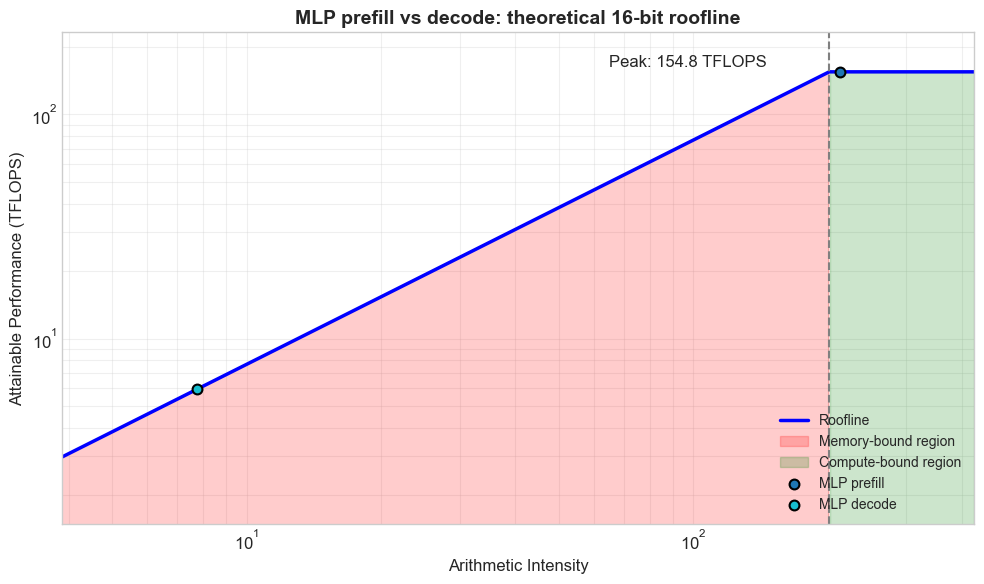

In [28]:
# ===== 【辅助修正】MLP 的16位 I/O 与16位参考屋顶线保持一致 =====
B = 8  # 本格保留原题的理论批大小，不分配真实输入。
D = GEMMA3_270M_CONFIG.hidden_size  # 隐藏维度。
I = GEMMA3_270M_CONFIG.intermediate_size  # 中间维度。
L_q = 2048  # prefill 理论长度。
mlp_prefill_flops = calc_mlp_flops(B, L_q, D, I)  # prefill 理论浮点运算量。
mlp_prefill_io = calc_mlp_io(B, L_q, D, I)  # 同形状的16位理论字节流量。
mlp_decode_flops = calc_mlp_flops(B, 1, D, I)  # 单 token 解码理论计算量。
mlp_decode_io = calc_mlp_io(B, 1, D, I)  # 解码理论字节流量。
ai_to_plot = {"MLP prefill": mlp_prefill_flops / mlp_prefill_io, "MLP decode": mlp_decode_flops / mlp_decode_io}  # 统一为 FLOPs/Byte。
tensor_peak = gpu_spec["bf16_tflops"] or gpu_spec["fp16_tflops"]  # 与16位元素流量对应的参考吞吐率。
ax = plot_roofline(gpu_name, tensor_peak, peak_bandwidth, ai_to_plot, title="MLP prefill vs decode: theoretical 16-bit roofline")  # 让曲线和标记使用同一上限。
print("理论算术强度：", ai_to_plot)  # 显示两阶段位置对应的数值。
print(f"16位参考拐点：{tensor_peak / peak_bandwidth:.3f} FLOPs/Byte")  # 标注相同单位的拐点。
plt.show()  # 显示图；坐标轴范围由16位峰值决定，避免上限曲线被截断。


**中文导读：结合当前形状解释图中的位置。**

Prefill 同时处理多个 token，权重有更多计算可以复用；小批次单 token 解码处理的计算较少，但仍要读取权重，算术强度可能偏低。

“prefill 常受算力限制、decode 常受带宽限制”是常见情形，不是所有配置的必然结论。批大小、序列长度、数据类型和实际硬件都会改变位置；应结合本实验实际选用的屋顶线和测量结果说明。

You can clearly see from the figure above that the bottleneck of MLP is very different on the two stages. During prefilling, the layer is compute-bound. During decoding, it becomes memory-bound. In fact, this is not restricted to MLP. It's an important feature of modern LLM whose inference can be divided into prefill and decode stages. The prefilling is usually compute-bound and decoding is usually memory bound.

#### Question 3.4.1 (5 points)

**中文题意：用自己的话解释两阶段的瓶颈差异。**

从输入 `[B, L, D]` 与 `[B, 1, D]` 出发，比较每次读取权重后服务了多少个 token。用“计算量与读写量的比例”把形状和屋顶线连接起来，而不仅写一个 compute-bound 或 memory-bound 标签。

Explain in words why the performance bottleneck of the MLP layer is different for prefilling and decoding. (Hint: think about the shapes of the query for prefilling and decoding, and how they are related to gemm and gemv)

**Your Answer:**

**【已补全·Q3.4.1 解释】**

MLP 接收 `[B,L,D]`。Prefill 的 L 通常较大，同一组权重可作用于 B×L 个 token，主要投影更接近矩阵乘矩阵；小批次单步 decode 的 L=1，可复用权重的 token 较少，更接近矩阵乘向量。

所以在常见配置下，prefill 的 FLOPs/Byte 较高、更可能接近算力限制，decode 的 FLOPs/Byte 较低、更容易受读取权重的带宽限制。增大解码 batch 会改变这个判断，最终应比较实际配置的算术强度与相应数据类型的屋顶线拐点。


#### Question 3.4.2 (5 points)

**中文题意：改变解码批大小 B，比较算术强度。**

对列表中的每个 B，重算 decode 的 FLOPs 和字节数，把结果放到同一张参考屋顶线上。固定长度为 1 和其他维度，观察增大同时处理的样本数会怎样改变权重读取的利用程度。

Vary the batch size (B) of the decoding stage and plot them on the same roofline. Describe your findings.

**Your Answer:**

**【已补全·Q3.4.2 解释】**

固定 L=1 时，增大 B 会增加一次使用同一组权重处理的 token 数；权重项不像激活项那样随 B 同比例增长，所以当前模型中的算术强度会上升，点向屋顶线右侧移动。

激活读写也在增长，因此不能把 B 增大后的 AI 永远视为正比增长。下一格打印各 B 的理论数值，并将它们画在同一条 16 位参考屋顶线上。


**【已补全·重点解释】Q3.4.2：改变解码 batch size**

固定单步长度 L=1，每次只改变批大小 B。更多样本共同使用同一组权重，可以提高按当前模型计算的算术强度；但激活读写也增长，因此提升不会无限线性持续。

曲线选择 BF16/FP16 参考上限，与 16 位 I/O 口径一致。仍沿用原题 A6000 理论配置，图中的点不代表本机实测吞吐。

 B  FLOPs/Byte
 1    0.997700
 4    3.936086
16   14.925836
64   49.425361


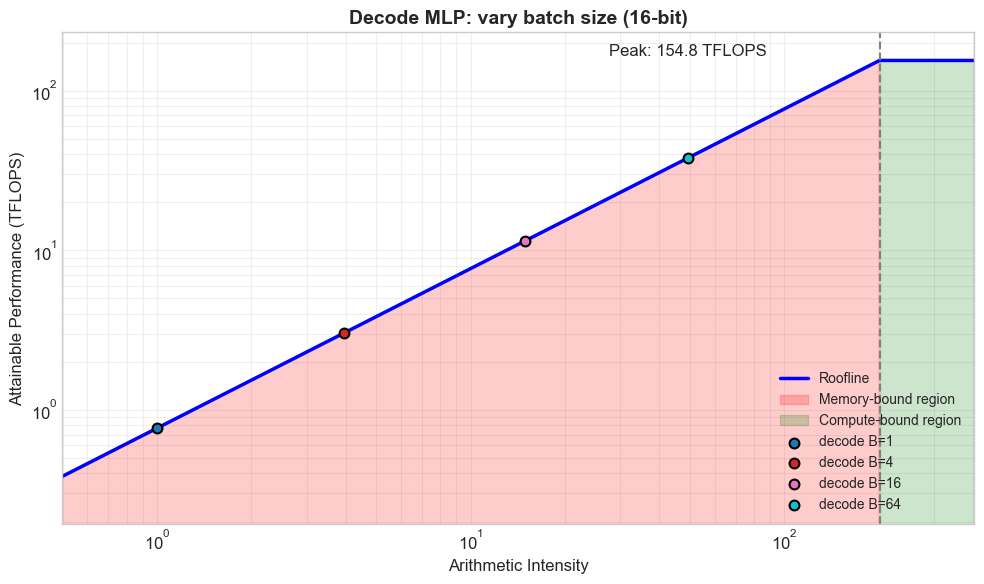

In [29]:
# ===== 【已补全】Q3.4.2：改变解码 batch size =====
Bs = [1, 4, 16, 64]  # 待比较的解码批大小。
D = GEMMA3_270M_CONFIG.hidden_size  # 隐藏维度。
I = GEMMA3_270M_CONFIG.intermediate_size  # MLP 中间维度。
L_q = 1  # 解码一步，每条样本只有一个新 token。
decode_batch_ai = {}  # 保存每个 B 对应的算术强度。
for batch in Bs:  # 避免覆盖全局 B，用 batch 表示本次枚举值。
    flops = calc_mlp_flops(batch, L_q, D, I)  # 计算该批大小下的理论运算量。
    io_bytes = calc_mlp_io(batch, L_q, D, I)  # 计算同形状下的 16 位理论读写量。
    decode_batch_ai[f"decode B={batch}"] = flops / io_bytes  # 保存 FLOPs/Byte。
tensor_peak = gpu_spec["bf16_tflops"] or gpu_spec["fp16_tflops"]  # 选择 16 位的理论吞吐参考。
print(pd.DataFrame({"B": Bs, "FLOPs/Byte": list(decode_batch_ai.values())}).to_string(index=False))  # 输出可核对的结果。
plot_roofline(gpu_name, tensor_peak, peak_bandwidth, decode_batch_ai, title="Decode MLP: vary batch size (16-bit)")  # 所有点放同一屋顶线。
plt.show()  # 显示图。


#### Question 3.4.3 (5 points)

**中文题意：固定批大小，改变 prefill 长度。**

逐个读取 Ls 中的长度，分别计算 FLOPs、I/O 与算术强度。先预测计算量和中间结果会怎样增长，再用图检验，不必预先认定每个点一定在拐点的同一侧。

Vary the prefill length (L_q) of the prefilling and plot them on the same roofline. Describe your findings.

**Your Answer:**

**【已补全·Q3.4.3 解释】**

固定 B 时，增大 prefill 长度 L 也会提高每次读取权重后的计算复用。按本实验 MLP 模型，算术强度先上升，随后逐渐接近由中间激活读写所决定的上限。

它是否从带宽区进入算力区，要比较具体 AI 与 16 位参考拐点；很长的输入也会增加激活显存，不能只根据 AI 推断可运行规模或实际延迟。


**【已补全·重点解释】Q3.4.3：改变 prefill 长度**

固定 B=32，改变 L，每次都重算 FLOPs 和 I/O。权重读入后可服务更多 token，算术强度先提高；随着中间激活的读写变得重要，增长逐渐趋缓。

这组图只改变输入长度，不切换模型维度或参考硬件，便于判断变化由什么引起。

   L  FLOPs/Byte
  64  194.886076
 256  209.826235
1024  213.926183
4096  214.976328


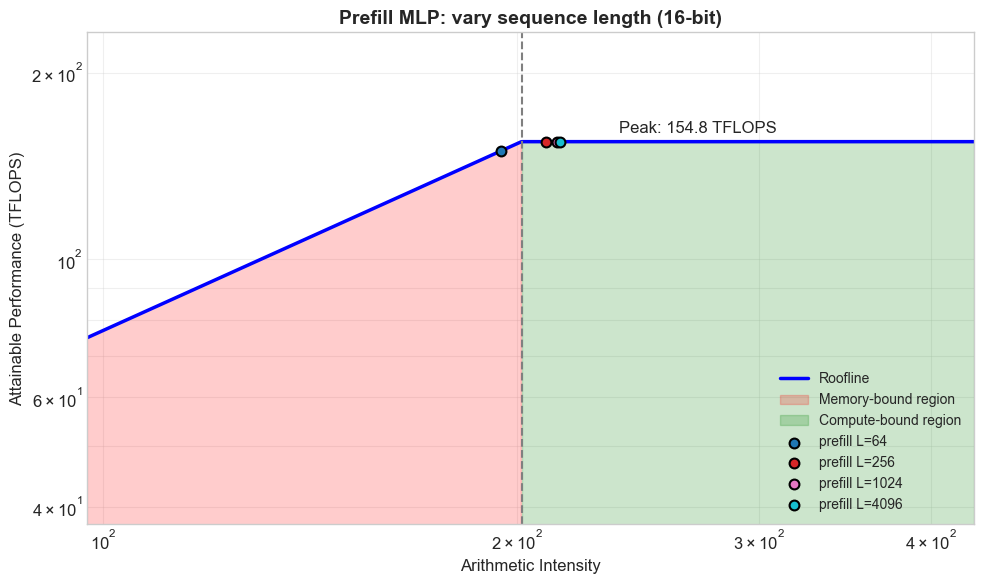

In [30]:
# ===== 【已补全】Q3.4.3：改变 prefill 长度 =====
B = 32  # 固定批大小，只研究序列长度的影响。
D = GEMMA3_270M_CONFIG.hidden_size  # 读取隐藏维度。
I = GEMMA3_270M_CONFIG.intermediate_size  # 读取 MLP 中间维度。
Ls = [64, 256, 1024, 4096]  # 待比较的提示词长度。
prefill_length_ai = {}  # 保存各长度对应的算术强度。
for length in Ls:  # 逐个测试理论输入长度。
    flops = calc_mlp_flops(B, length, D, I)  # 理论浮点运算量。
    io_bytes = calc_mlp_io(B, length, D, I)  # 理论读写字节数。
    prefill_length_ai[f"prefill L={length}"] = flops / io_bytes  # 按相同口径换算算术强度。
tensor_peak = gpu_spec["bf16_tflops"] or gpu_spec["fp16_tflops"]  # 16 位理论计算上限。
print(pd.DataFrame({"L": Ls, "FLOPs/Byte": list(prefill_length_ai.values())}).to_string(index=False))  # 展示各点数值。
plot_roofline(gpu_name, tensor_peak, peak_bandwidth, prefill_length_ai, title="Prefill MLP: vary sequence length (16-bit)")  # 画参考屋顶线。
plt.show()  # 显示图。


# Part 4: Profiling with PyTorch Profiler

**中文导读：Profiler 是查看“时间具体花在哪里”的工具。**

总延迟只给出一个数；性能分析器还能记录算子、CPU 提交、CUDA 内核和内存相关活动。重点观察：有哪些操作、调用多少次、时间是否集中在少数内核，以及中间是否存在明显空隙。

PyTorch Profiler is a built-in performance analysis tool that helps you understand where time and memory are spent in your models. It captures detailed metrics including CPU and CUDA kernel execution times, memory allocations, and call stacks. 

## 4.1 Basic Profiling

**中文导读：先用一次简单矩阵乘法熟悉分析器。**

`with ... as prof` 表示进入分析上下文，并用 prof 保存分析器对象。`prof.step()` 向分析器报告“一步已经完成”。本实验 `default_schedule` 定义在 [utils/benchmark.py](utils/benchmark.py)：等待 1 步、预热 3 步、正式记录 6 步，共 10 步。

Let's profile the matmul function using the Pytorch profiler

In [31]:
# ===== 【辅助修正】复用统一预热与分析日程 =====
A = torch.randn(128, 128, dtype=half_dtype, device=device)  # 16位左矩阵。
B = torch.randn(128, 128, dtype=half_dtype, device=device)  # 同设备同类型右矩阵。
prof = profile_for_lab(torch.matmul, A, B, trace_name="matmul")  # 打印分析表并导出真实时间线。


【采集限制】本次 trace 仅含 CPU 操作与提交；CUDA 内核时间线和调用数没有被采集。
-----------------  ------------  ------------  ------------  ------------  ------------  ------------  
             Name    Self CPU %      Self CPU   CPU total %     CPU total  CPU time avg    # of Calls  
-----------------  ------------  ------------  ------------  ------------  ------------  ------------  
    ProfilerStep*        39.28%     539.100us       100.00%       1.373ms     228.767us             6  
     aten::matmul        12.77%     175.300us        60.72%     833.500us     138.917us             6  
         aten::mm        47.95%     658.200us        47.95%     658.200us     109.700us             6  
-----------------  ------------  ------------  ------------  ------------  ------------  ------------  
Self CPU time total: 1.373ms

时间线文件： e:\SKILLS\Course-TinyML\lab1_gpu_basics\outputs\matmul.json
【采集限制】未记录到 CUDA 内核；可读 CPU 事件，但不能据此推断 GPU 内核为零。


**中文导读：区分 Python 算子名与 CUDA 内核名。**

`torch.matmul` 是你调用的接口；下面的名称是框架实际选中的 GPU 实现。硬件、矩阵形状、类型和软件版本不同，内核名也可能不同。读表时先看调用次数、总 CUDA 时间和平均时间，再逐步研究名称含义。

You can see what CUDA kernels are actually being called. Name of CUDA kernel tells us something about the implementation. For example, nvjet_tst_64x8_64x16_2x4_v_bz_NNT refers to the actual kernel being used for matmul operation. (The exact kernel names depend on your GPU and PyTorch version, so you may see different ones.)

## 4.2 Profiling MLP

**中文导读：分析 MLP 内部的多步计算。**

同一个 MLP 调用会经过多个线性投影、激活和逐元素乘法，可能触发多个 GPU 内核。下一格将模型参数与输入都转换到 half_dtype，避免输入和权重类型不一致。

Next, let's profile something more complex. We again use our MLP layer for profiling.

In [32]:
# ===== 【辅助修正】所有推理对比统一 no_grad，避免无意保留反向图 =====
batch_size = 1 if LEARNING_MODE else 4  # 学习配置减少输入规模。
seq_len = 128 if LEARNING_MODE else 1024  # 扩展配置保留课程规模。
hidden_size = GEMMA3_270M_CONFIG.hidden_size  # 从相同模型配置读取维度。
x = torch.randn(batch_size, seq_len, hidden_size, dtype=half_dtype, device=device)  # 创建固定输入。
mlp = Gemma3MLP(GEMMA3_270M_CONFIG).to(device=device, dtype=half_dtype).eval()  # 创建评估状态的 MLP。
prof = profile_for_lab(mlp, x, trace_name="mlp_initial")  # helper 内部使用 no_grad，输出表和 trace。


【采集限制】本次 trace 仅含 CPU 操作与提交；CUDA 内核时间线和调用数没有被采集。
----------------------  ------------  ------------  ------------  ------------  ------------  ------------  
                  Name    Self CPU %      Self CPU   CPU total %     CPU total  CPU time avg    # of Calls  
----------------------  ------------  ------------  ------------  ------------  ------------  ------------  
         ProfilerStep*        32.59%     999.800us       100.00%       3.068ms     511.267us             6  
          aten::linear         1.76%      54.100us        58.62%       1.798ms      99.900us            18  
          aten::matmul        10.72%     328.800us        41.04%       1.259ms      69.944us            18  
              aten::mm        27.38%     839.900us        27.38%     839.900us      46.661us            18  
               aten::t         8.06%     247.400us        15.81%     485.100us      26.950us            18  
       aten::transpose         6.97%     213.900us         7.75%     237.700us 

**中文导读：把汇总表换成时间线观察。**

导出 `trace.json` 后，在 [Perfetto](https://ui.perfetto.dev/) 中打开这个文件。文件写到内核当前工作目录；可以从单元格的运行环境确认路径。

时间线能展示操作先后与重叠关系，适合观察 CPU 提交和 GPU 执行之间的空隙；单纯把汇总表各行相加，不一定等于完整端到端时间。

You can see that there are a lot more kernels being invoked this time. In fact, we can visualize the operation timeline in a nicer way. First, save the trace file of the profiler by `prof.export_chrome_trace("trace.json")`. Then, go to (copy paste https://ui.perfetto.dev/ in browser if unable to open the link) and upload the file. You will then see the following diagram.

In [33]:
# ===== 【辅助修正】为原题保留一个明确的 MLP trace 文件 =====
import shutil  # 导入标准库文件复制工具。
shutil.copyfile(lab_output_dir / "mlp_initial.json", lab_output_dir / "mlp_trace.json")  # helper 已导出一次；复制现有 trace，避免同一 Kineto 结果重复导出报错。
print("在 Perfetto 中打开：", lab_output_dir / "mlp_trace.json")  # 显示实际文件位置。


在 Perfetto 中打开： e:\SKILLS\Course-TinyML\lab1_gpu_basics\outputs\mlp_trace.json


**中文看图提示：** 沿横向时间轴寻找矩阵乘法、激活和逐元素乘法对应的区段，观察操作之间是否存在空隙。此处是课程示意图，具体名称和时间比例应以你导出的 trace 为准。

![alt text](./assets/mlp_tracing.png)

#### Bonus 4.2 (2.5 points)

**中文题意：分析完整 decoder 层的解码过程。**

复用已经准备好的输入、位置编码与缓存，再把前向计算放进 profiler 上下文。先确认前面的解码演示可以单独执行，并注意此实验需要的显存；报告你实际采集的时间线。

Can you profile the decoding stage of the full decoder layer and show the timeline visualization?

**【本次实际验证记录·2026-11-16】**

完整 decoder 的小规模解码已实际执行，时间线保存为 [outputs/decoder_decode.json](outputs/decoder_decode.json)。当前构建只采集到 CPU 操作/提交，未采集 CUDA 内核时间线；不能把这份文件称为已验证的 GPU 内核时间线。


**【已补全·重点解释】Bonus 4.2：完整 decoder 单步解码的时间线**

重新建立一个小规模 decoder、前缀和缓存，不依赖第 3.3 节已经删除的变量。先 prefill 一次，再反复测固定的同一解码位置，避免基准运行时历史越来越长。

所有前向都在推理状态下进行，时间线写入 `outputs/decoder_decode.json`。它包含归一化、投影、注意力、残差及 MLP 等操作；要结合事件看它们的先后和耗时。

In [34]:
# ===== 【已补全】Bonus 4.2：完整 decoder 单步解码的时间线 =====
profile_layer = Gemma3DecoderLayer(GEMMA3_270M_CONFIG, 5).to(device=device, dtype=half_dtype).eval()  # 构造单独的完整层。
profile_rope = Gemma3RotaryEmbedding(GEMMA3_270M_CONFIG, layer_type="full_attention").to(device)  # 准备本层位置编码。
prefix_len = 128  # 使用容易在本机运行的短前缀。
prefix_x, prefix_ids = create_prefill_inputs(1, prefix_len, GEMMA3_270M_CONFIG.hidden_size, dtype=half_dtype, device=device)  # 一条前缀输入。
prefix_emb = get_position_embeddings(prefix_x, prefix_ids, profile_rope, layer_type="full_attention")  # 完整前缀的 RoPE。
profile_cache = initialize_kv_cache(GEMMA3_270M_CONFIG, max_cache_len=prefix_len + 1)  # 为新 token 额外预留一个位置。
prefill_forward(profile_layer, prefix_x, prefix_ids, prefix_emb, profile_cache)  # 先真正建立历史 K/V。
step_x, step_ids, step_positions = create_decode_inputs_with_cache(1, prefix_len, GEMMA3_270M_CONFIG.hidden_size, dtype=half_dtype, device=device)  # 准备当前单 token。
step_emb = get_position_embeddings(step_x, step_ids, profile_rope, layer_type="full_attention")  # 当前 token 的 RoPE。
prof_decoder = profile_for_lab(decode_forward, profile_layer, step_x, step_ids, step_emb,  # 传入固定的同一解码token及位置。
    True, profile_cache, step_positions, None, trace_name="decoder_decode")  # 完整 decoder 解码前向，导出真实分析。
del prefix_x, prefix_ids, prefix_emb, profile_cache, step_x, step_ids, step_positions, step_emb  # 删除本段不再使用的张量引用。


【采集限制】本次 trace 仅含 CPU 操作与提交；CUDA 内核时间线和调用数没有被采集。
-------------------------------------------------  ------------  ------------  ------------  ------------  ------------  ------------  
                                             Name    Self CPU %      Self CPU   CPU total %     CPU total  CPU time avg    # of Calls  
-------------------------------------------------  ------------  ------------  ------------  ------------  ------------  ------------  
                                    ProfilerStep*         3.53%     840.700us       100.00%      23.786ms       3.964ms             6  
                                        self_attn        12.33%       2.933ms        53.56%      12.740ms       2.123ms             6  
                                         aten::to         1.37%     326.400us        14.54%       3.457ms      24.010us           144  
                                   aten::_to_copy         4.02%     956.200us        13.16%       3.131ms      28.991us           108  

## 4.3 Kernel Fusion

**中文导读：Kernel fusion（内核融合）想减少什么？**

一个 CUDA kernel 是 GPU 执行的一段计算。逐个启动很多小内核会产生提交开销；若每一步还把中间结果写回显存，再由下一步读入，就会增加数据搬运。

融合把可以组合的计算放在较少的内核中，有机会同时减少启动次数与中间显存读写。图中“工厂”代表计算单元，“仓库”代表显存。

As you can see from the profiling results, one simple operation could lead to a number of kernel launches. Each kernel launch takes time, thus too many launches result in overhead. This motivates us to fuse many kernels into one "large" kernel. Another benefit of kernel fusion is to reduce I/O overhead. You can read a very nice [blog post](https://horace.io/brrr_intro.html) by Horace He. We have extracted the main idea below for your reference.

We can model the relationship between our memory and compute as factory(compute) and warehouse(memory)

<img src="./assets/kernel_fusion_1.png" width=60%>

**中文看图提示：** 对大型张量做一次逐元素 cos，单个元素需要的计算相对少，但数据仍要读取和写回。这样的算子经常受到显存带宽影响。若连续执行多步逐元素操作，每一步都读写中间张量，数据搬运成本会累积。

Now, imagine what happens when we perform an unary operation like `torch.cos`. We need to ship our data from our storage to the warehouse, then perform a tiny bit of computation for each piece of data, and then ship that storage back. Shipping things around is quite expensive. As a result, nearly all of our time here is spent shipping data around, and not on the actual computation itself.

Since we're spending all of our time on memory-bandwidth, such an operation is called a memory-bound operation, and it means that we're not spending a lot of time on compute.

Ok, so that's not ideal. What can we do about it? Let's take a look at how a sequence of operators might look.

<img src="./assets/kernel_fusion_2.png" width=60%>

**中文看图提示：** 融合后的思路是读取一块数据后，尽量在靠近计算单元的位置完成后续操作，最后再写回结果。实际能否融合取决于算子关系与实现，不能仅凭 Python 里写成一行就断定只有一个内核。

This is a very stupid arrangement. Why are we sending the same data to global memory and then back to the compute units, over and over? We should just keep the data at the factory, perform all of our compute, and then send it back! That's actually the spirit of fusion.

<img src="./assets/kernel_fusion_3.png" width="60%">

**中文题意：把公式逐项翻译成张量运算，实现 tanh 近似 GeLU。**

先看清乘法、加法、三次方、平方根和 tanh 的顺序。对张量使用 `*` 是逐元素乘法；Python 的幂是 `**`，不是 `^`。这一题已展开数学计算；随后与 `F.gelu(x, approximate="tanh")` 比较。

Now, let's see the actual speedup that kernel fusion can bring to us.

#### Question 4.3.1 (3 points)

Here is the mathematical equation of the GeLU activation function:

$$\text{GELU}(x) \approx 0.5x\left[1 + \tanh\left(\sqrt{\frac{2}{\pi}}(x + 0.044715x^3)\right)\right]$$

Please implement this function using PyTorch. You can only use torch API for tanh and math operations such as power and square root. 


**【已补全·重点解释】Q4.3.1：展开 tanh 近似 GeLU**

按原公式逐项展开，便于观察多次逐元素运算会触发怎样的内核。`input.pow(3)` 是三次方；`torch.tanh` 对每个元素求双曲正切。

常数张量放到输入同一设备、使用同一类型，避免 CPU/GPU 混用。这个实现用于学习与对比，可能产生多个中间张量；内置 GeLU 或编译器有机会把这些步骤合并。

In [35]:
# ===== 【已补全】Q4.3.1：展开 tanh 近似 GeLU =====
def gelu_tanh_python(input):  # 输入输出保持相同的形状、设备和数值类型。
    coefficient = torch.sqrt(input.new_tensor(2.0 / torch.pi))  # 用输入的设备与类型创建常数，再计算 √(2/π)。
    cubic = input.pow(3)  # 对每个输入元素计算 x³。
    inner = input + 0.044715 * cubic  # 计算括号中的 x + 0.044715x³。
    tanh_value = torch.tanh(coefficient * inner)  # 对缩放后的表达式逐元素求 tanh。
    return 0.5 * input * (1.0 + tanh_value)  # 按公式得到激活输出。


#### Question 4.3.2 (2 points) 

**中文题意：用相同输入比较两种 GeLU 的延迟。**

手写公式和内置版本都选择 tanh 近似，并使用相同设备、类型、预热与重复次数。输出标签写的是 ms：若调用 `latency`，需要把秒换算成毫秒；若调用 `benchmark_latency`，返回值已经是毫秒。

Benchmark the latency of your GeLU and PyTorch implemented GeLU. 

**【已补全·重点解释】Q4.3.2：测两种 GeLU 的延迟**

通过 `partial` 为内置函数固定 `approximate="tanh"`，保证两者计算的是相同近似。先做数值一致性检查，再测速度。复用 `latency` 返回的秒数后统一乘 1000，打印成毫秒。

本次加速比由实际读数计算，大于 1 表示内置版本更快。它依赖本机和当前输入规模，并不是固定答案。

In [36]:
# ===== 【已补全】Q4.3.2：测两种 GeLU 的延迟 =====
import functools  # partial 可以提前固定函数的某个关键字参数。
x = torch.randn(1_000_000, device=device)  # 创建一百万个元素，放到当前选定设备。
builtin_gelu = functools.partial(F.gelu, approximate="tanh")  # 构造与手写公式对应的内置函数。
torch.testing.assert_close(gelu_tanh_python(x), builtin_gelu(x), rtol=1e-4, atol=1e-6)  # 先确认数值足够接近。
python_gelu_latency = latency(gelu_tanh_python, x, warmup=10, repeat=50) * 1000  # 手写版本，秒转毫秒。
pytorch_gelu_latency = latency(builtin_gelu, x, warmup=10, repeat=50) * 1000  # 内置版本使用相同计时设置。
print(f"Python GeLU latency: {python_gelu_latency:.6f} ms")  # 打印实际测量结果。
print(f"PyTorch GeLU latency: {pytorch_gelu_latency:.6f} ms")  # 打印内置版本实际结果。
print(f"本次内置版本加速比：{python_gelu_latency / pytorch_gelu_latency:.2f}×")  # 用本次读数计算加速比。


Python GeLU latency: 0.602439 ms
PyTorch GeLU latency: 0.104753 ms
本次内置版本加速比：5.75×


#### Question 4.3.3 (2 points)

**中文题意：记录你观察到的结果。**

写出两种实现实际的延迟及测试条件，再提出可能原因。一次实验不能代表所有输入规模；接下来用 profiler 检查内核调用与读写过程，给解释增加证据。
Describe your findings

**Your Answer:**

**【已补全·Q4.3.3 解释与结果口径】**

第 4.3.2 节会输出本机两种实现的真实毫秒延迟与加速比。手写公式显式产生 pow、mul、add、tanh 等中间步骤；内置 GeLU 有机会使用更紧凑的实现，从而减少内核启动与中间张量读写。

这是需要 profiler 支持的性能解释，不能仅凭公式行数推断内核数或保证加速比。两者须使用相同输入、近似方式和计时口径。


**【本次实际验证记录·2026-11-16】**

一百万个 FP32 元素：手写 GeLU 0.4966 ms，内置 tanh GeLU 0.0751 ms，本次内置加速比 6.61×。这里用 CUDA Event 计时，不能与前面 CPU 手写矩阵的端到端口径直接比较。


#### Question 4.3.4 (5 points)

**中文题意：用 profiler 支持你的速度解释。**

分别分析手写和内置版本，比较内核数、调用次数及 CUDA 时间，必要时导出时间线。保持输入与分析日程一致，把正式记录窗口与预热阶段区分开。

Use PyTorch's profiler to explain your findings (please show your profiling code and results)

**Your Answer:**

**【已补全·Q4.3.4 分析方法】**

分别记录手写与内置版本的同一段稳定执行窗口，比较 CUDA 内核调用数和时间。若内置实现将逐元素步骤合并，时间线通常能看到更少的分散内核与中间开销；具体内核名称和次数以本次输出为准。

下一格已给出完整分析代码并导出 `outputs/gelu_python.json` 与 `outputs/gelu_builtin.json`。记录窗口是 6 个 active 步，汇总次数不是自动换算后的单次前向数。


**【本次实际验证记录·2026-11-16】**

当前 PyTorch 2.6.0+cu126 构建的 Profiler 仅支持 CPU 活动，已导出两份真实 CPU 操作/提交 trace；没有采集到 CUDA 内核事件，因此 GPU 内核调用数及其时间未知，统计工具中的零不能作为“零次 GPU 内核”的结论。前面的 CUDA Event 延迟测量独立有效。


**【已补全·重点解释】Q4.3.4：分别分析两种 GeLU**

复用准备区定义的 `profile_for_lab`，在正式记录前预热，记录相同的 6 个 active 步，并各自导出 trace。观察手写公式的 pow、mul、add、tanh 等操作，与内置版本实际触发的内核对比。

输出字典统计的是记录窗口的总调用数；判断每次前向时应结合 active=6 的窗口长度。若环境没有采集到 CUDA 事件，代码会显示这一限制，不能把零当成“GPU 没做计算”。

In [37]:
# ===== 【已补全】Q4.3.4：分别分析两种 GeLU =====
prof_python_gelu = profile_for_lab(gelu_tanh_python, x, trace_name="gelu_python")  # 分析手写逐元素公式。
prof_builtin_gelu = profile_for_lab(builtin_gelu, x, trace_name="gelu_builtin")  # 用相同输入分析内置版本。
python_gelu_kernels = count_cuda_kernels(prof_python_gelu)  # 汇总手写版本记录到的 CUDA 内核。
builtin_gelu_kernels = count_cuda_kernels(prof_builtin_gelu)  # 汇总内置版本记录到的 CUDA 内核。
print("手写 GeLU：", python_gelu_kernels)  # 输出分类与总调用数。
print("内置 GeLU：", builtin_gelu_kernels)  # 输出对应统计，结合时间线解释差异。


【采集限制】本次 trace 仅含 CPU 操作与提交；CUDA 内核时间线和调用数没有被采集。
-----------------------  ------------  ------------  ------------  ------------  ------------  ------------  
                   Name    Self CPU %      Self CPU   CPU total %     CPU total  CPU time avg    # of Calls  
-----------------------  ------------  ------------  ------------  ------------  ------------  ------------  
          ProfilerStep*        18.46%     806.500us       100.00%       4.369ms     728.100us             6  
               aten::to         0.29%      12.500us        57.23%       2.500ms     208.358us            12  
         aten::_to_copy         2.75%     120.100us        56.95%       2.488ms     414.633us             6  
            aten::copy_        53.70%       2.346ms        53.70%       2.346ms     391.017us             6  
              aten::mul         8.96%     391.500us         8.96%     391.500us      16.312us            24  
              aten::pow         5.72%     249.700us         5.78%     2

## 4.4 `torch.compile` and CUDA Graph

**中文导读：先理解编译包装与首次运行。**

`torch.compile` 创建优化执行的包装，主要编译工作通常在首次收到实际输入时触发。它可能减少 Python 调度开销并融合合适的运算，但不保证所有代码都能编译或所有场景都更快。

比较时区分首次编译耗时与稳定执行耗时，并查看警告和 profiler 结果。编译后端的可用性取决于当前系统、依赖和 GPU；语法检查通过并不代表编译实验已成功运行。

torch.compile is PyTorch's way of speeding up your model by converting eager-mode Python code into optimized kernels. When you wrap a model with torch.compile(model), PyTorch traces the operations, fuses them where possible, and generates efficient Triton or C++ kernels behind the scenes. This reduces Python overhead and combines multiple small operations into fewer, larger kernels—meaning fewer kernel launches and better GPU utilization.

**中文导读：先观察编译对手写 GeLU 的影响。**

下一格分析 compiled_gelu；第一批调用可能包含编译，未编译好的函数也不会因预热步数固定就必然完成所有准备。需要结合记录窗口判断测到的是编译过程还是稳定执行。

In the cell below, we first compile the GeLU function you just implemented and see how your GeLU is optimized.

In [38]:
# ===== 【辅助修正】在 profiler 之外完成首次编译；不可用时明确报告 =====
x = torch.randn(1_000_000, device=device)  # 与未编译 GeLU 使用相同形状和类型。
compiled_gelu = prepare_compiled(gelu_tanh_python, x, name="gelu")  # 真正执行后才判断编译是否成功。
if compiled_gelu is None:  # 无可用 GPU 编译后端时，保留未运行状态。
    print("【未运行 GeLU 编译实验】", compile_status["gelu"])  # 不打印虚构的 compiled 性能。
else:  # 有真实可执行的编译对象才继续分析。
    prof_compiled_gelu = profile_for_lab(compiled_gelu, x, trace_name="gelu_compiled")  # 使用稳定的分析窗口。


【采集限制】本次 trace 仅含 CPU 操作与提交；CUDA 内核时间线和调用数没有被采集。
--------------------------------------------  ------------  ------------  ------------  ------------  ------------  ------------  
                                        Name    Self CPU %      Self CPU   CPU total %     CPU total  CPU time avg    # of Calls  
--------------------------------------------  ------------  ------------  ------------  ------------  ------------  ------------  
                               ProfilerStep*        28.80%     329.900us       100.00%       1.145ms     190.917us             6  
                  Torch-Compiled Region: 0/0        48.61%     556.800us        68.33%     782.700us     130.450us             6  
    triton_poi_fused_add_mul_pow_sqrt_tanh_0        19.72%     225.900us        19.72%     225.900us      37.650us             6  
                    TorchDynamo Cache Lookup         2.87%      32.900us         2.87%      32.900us       5.483us             6  
----------------------------------

**中文导读：把同样的方法用到 MLP。**

这里选 `max-autotune-no-cudagraphs`，让后续可以分别讨论自动调优/融合与 CUDA Graphs 的作用。自动调优是否实际启用、选择了什么实现，会受硬件能力和具体算子影响，观察本机日志即可，不必追求与示例完全同名的内核。

Now, let's compile the MLP layer.

Note: on GPUs with few SMs, such as the Colab T4, `max-autotune` does not autotune the matmuls (you may see "Not enough SMs to use max_autotune_gemm mode"), so the main visible change is the fusion of the element-wise ops.

In [39]:
# ===== 【辅助修正】编译前后共享同一模型参数与同一输入 =====
mlp_eager = Gemma3MLP(GEMMA3_270M_CONFIG).to(device=device, dtype=half_dtype).eval()  # 建立未编译的基准对象。
mlp_input = torch.randn(1 if LEARNING_MODE else 4, 128 if LEARNING_MODE else 1024,  # 前两维依次为批大小和序列长度。
    GEMMA3_270M_CONFIG.hidden_size, device=device, dtype=half_dtype)  # 固定输入供前后对照。
compiled_mlp = prepare_compiled(mlp_eager, mlp_input, name="mlp", mode="max-autotune-no-cudagraphs")  # 先预热，再交给下一格分析。


W1116 14:59:13.244000 4120 site-packages\torch\_inductor\utils.py:1137] [1/0] Not enough SMs to use max_autotune_gemm mode


#### Question 4.4.1 (3 points)

**中文题意：用同样输入比较编译前后的 MLP。**

调用编译包装后的对象 `compiled_mlp`，并与前面未编译版本的分析结果对照。记录内核数和主要耗时变化，同时区分首次编译成本；不要只凭模型被包装就认定已经加速。

Profile the MLP again and describe the difference between the uncompiled version.

**Your Answer:**

**【已补全·Q4.4.1 解释与未运行规则】**

使用同一模型参数、同一输入和 `no_grad` 条件比较 eager 与 compiled。编译准备在分析窗口外完成；若发生融合，可能减少逐元素内核和中间读写，但矩阵乘法未必变成同一个内核。

当前环境能否执行 GPU 编译由 `prepare_compiled` 实际检查。若输出“未运行”，表示本次没有编译后的测量数据，不能填写为已加速；编译路径与 profiler 代码已经完整提供，安装兼容后端后可重跑。


**【本次实际验证记录·2026-11-16】**

当前环境没有可用的 Triton，未执行 GPU 编译实验。本次没有编译后延迟或内核数；完整代码已保留。


**【已补全·重点解释】Q4.4.1：分析编译后的 MLP**

先在分析窗口外完成首次编译与预热，再使用与未编译版本相同的模型、输入和推理状态做比较。这样不会把编译阶段的耗时直接当成稳定运行性能。

编译不受支持时会明确显示“未运行”，保留完整分析代码，不拿 eager 版本冒充编译结果。

In [40]:
# ===== 【已补全】Q4.4.1：分析编译后的 MLP =====
if compiled_mlp is None:  # 准备区已记录编译后端是否可用。
    print("【未运行编译实验】", compile_status["mlp"])  # 明确说明未实际采集编译后数据。
else:  # 编译包装已成功执行并预热后才测量。
    prof_eager_mlp = profile_for_lab(mlp_eager, mlp_input, trace_name="mlp_eager")  # 分析相同参数的未编译对象。
    prof_compiled_mlp = profile_for_lab(compiled_mlp, mlp_input, trace_name="mlp_compiled")  # 分析编译包装。
    eager_ms = latency(mlp_eager, mlp_input, warmup=3, repeat=20) * 1000  # 记录未编译的稳定延迟。
    compiled_ms = latency(compiled_mlp, mlp_input, warmup=3, repeat=20) * 1000  # 记录编译后的稳定延迟。
    print(f"eager={eager_ms:.4f} ms, compiled={compiled_ms:.4f} ms")  # 只输出本次真实测量值。


【采集限制】本次 trace 仅含 CPU 操作与提交；CUDA 内核时间线和调用数没有被采集。
----------------------  ------------  ------------  ------------  ------------  ------------  ------------  
                  Name    Self CPU %      Self CPU   CPU total %     CPU total  CPU time avg    # of Calls  
----------------------  ------------  ------------  ------------  ------------  ------------  ------------  
         ProfilerStep*        34.00%     336.800us       100.00%     990.700us     165.117us             6  
          aten::linear         2.78%      27.500us        54.81%     543.000us      30.167us            18  
          aten::matmul         5.31%      52.600us        46.05%     456.200us      25.344us            18  
              aten::mm        36.76%     364.200us        36.76%     364.200us      20.233us            18  
            aten::gelu         6.57%      65.100us         6.57%      65.100us      10.850us             6  
               aten::t         3.03%      30.000us         5.99%      59.300us 

**中文导读：融合与 CUDA Graphs 关注的开销不同。**

融合主要减少分散的计算内核及中间读写；CUDA Graphs 记录可重复的 GPU 工作序列，之后以较少的 CPU 提交工作重放。它可以减少 CPU 发起多次内核调用的成本，但不是让数学运算自动消失。

是否能捕获和重放取决于输入、内存及执行路径等条件；下一格的模式只是请求相应优化，实际结果要看时间线。

torch.compile reduces the number of kernel launches by fusing operations, but the CPU still has to dispatch each remaining kernel individually every forward pass. CUDA graphs go further by recording the entire launch sequence once, then replaying it with a single CPU call. This means the CPU spends almost no time on launch overhead—it just triggers the whole graph.

In [41]:
# ===== 【辅助修正】单独准备请求 CUDA Graphs 的模式 =====
graph_eager = Gemma3MLP(GEMMA3_270M_CONFIG).to(device=device, dtype=half_dtype).eval()  # 建立独立模型，避免与上段编译状态混用。
graph_input = torch.randn_like(mlp_input)  # 创建同形状的固定输入，重复调用保持对象与地址稳定。
graph_mlp = prepare_compiled(graph_eager, graph_input, name="graph_mlp", mode="max-autotune")  # 实际是否捕获并重放需看 trace。
print(compile_status["graph_mlp"])  # 显示本机真实准备状态。


已实际调用并预热，mode=max-autotune；CUDA Graphs 是否重放仍需看 trace。


#### Bonus 4.4.2 (2.5 points)

**中文题意：分析启用 CUDA Graphs 优化后的 MLP 时间线。**

按题目要求，在 `with torch.no_grad():` 内执行分析用的前向，避免保留待反向计算的图影响重放。注意 no_grad 关闭梯度记录，而 `model.eval()` 改变某些层的训练/评估行为，两者用途不同。

Profile the MLP compiled with CUDA again and show the timeline visualization below. Run the profiled forward passes under `with torch.no_grad():`, otherwise the CUDA Graphs are not replayed.

**【本次实际验证记录·2026-11-16】**

当前环境没有可用的 Triton，未执行 GPU 编译实验。本次没有 CUDA Graphs 重放的实测时间线。


**【已补全·重点解释】Bonus 4.4.2：分析 CUDA Graphs 编译模式**

这次请求 `max-autotune` 模式，并在 `no_grad` 下预热和记录。通过导出的时间线确认是否出现图捕获/重放及 CPU 提交的变化；选择模式本身不能证明图重放已经发生。

使用同一个输入对象、固定形状和单独的预热阶段。编译不可用时清楚标注，不生成假的速度或内核数。

In [42]:
# ===== 【已补全】Bonus 4.4.2：分析 CUDA Graphs 编译模式 =====
if graph_mlp is None:  # 检查包含 CUDA Graphs 优化的编译包装是否成功准备。
    print("【未运行 CUDA Graphs 编译实验】", compile_status["graph_mlp"])  # 显示未运行原因。
else:  # 仅分析真实成功执行的包装对象。
    prof_graph_mlp = profile_for_lab(graph_mlp, graph_input, trace_name="mlp_compile_cudagraphs")  # helper 内部使用 no_grad。
    graph_ms = latency(graph_mlp, graph_input, warmup=3, repeat=20) * 1000  # 测稳定运行的毫秒延迟。
    print(f"CUDA Graphs 模式实际延迟：{graph_ms:.4f} ms")  # 具体是否重放仍需结合导出 trace 判断。


【采集限制】本次 trace 仅含 CPU 操作与提交；CUDA 内核时间线和调用数没有被采集。
------------------------------  ------------  ------------  ------------  ------------  ------------  ------------  
                          Name    Self CPU %      Self CPU   CPU total %     CPU total  CPU time avg    # of Calls  
------------------------------  ------------  ------------  ------------  ------------  ------------  ------------  
                 ProfilerStep*        23.35%     235.300us       100.00%       1.008ms     167.983us             6  
    Torch-Compiled Region: 1/1        54.40%     548.300us        73.78%     743.600us     123.933us             6  
          aten::_foreach_copy_        11.47%     115.600us        11.47%     115.600us      19.267us             6  
                   aten::fill_         7.91%      79.700us         7.91%      79.700us       6.642us            12  
      TorchDynamo Cache Lookup         2.88%      29.000us         2.88%      29.000us       4.833us             6  
---------------

# Part 5: Flash Attention

**中文导读：本部分比较手写标准注意力与融合实现。**

第 5 部分属于原课的加分内容，依赖较新的兼容 GPU 与相应 Flash Attention 安装。硬件不足时可以先读形状变化、显存增长与融合思想，之后再运行大规模实验。

要区分本 notebook 自定义的 `scaled_dot_product_attention` 与 `torch.nn.functional.scaled_dot_product_attention`：前者由你在练习中展开计算，后者是 PyTorch 接口，会按条件选择底层实现。

In this section, we will learn flash attention and know how it improves the standard attention.

**IMPORTANT: This section is now a bonus module because it cannot be executed on the standard Colab T4 GPU. We have made this change to ensure you don't face GPU availability issues as the deadline approaches. However, we highly encourage you to explore it if you have the resources; Flash Attention is a pivotal technique in the modern LLM era.**


**中文导读：先观察显式保存注意力矩阵的代价。**

接下来使用的是本 notebook 的手写标准注意力函数。它若按题意显式生成 `[B, H, L, L]` 的中间矩阵，序列变长时显存需求会迅速增加；这不能直接代表所有内置 SDPA 后端的行为。

## 5.1 Limitation of SDPA

**中文运行提示：** 先完成第 3.1 节的注意力实现。下一格逐步增大序列长度，并捕获显存不足异常；开始时应关注本机显存容量和已有张量占用。原工具 benchmark_memory 报告总峰值；本版实验使用 extra_peak_memory_gb 扣除调用前基线，报告新增峰值，且把容量估计后跳过与实测 OOM 分开记录。

Now, let's see what's the limitation of the standard scale-dot-product attention (SDPA).

In [43]:
# ===== 【辅助修正】记录实际成功/跳过状态，避免8GB机器盲目分配超大矩阵 =====
memory_rows = []  # 保存每个长度的状态和已实际测到的显存。
for seq_len in [512, 1024, 2048, 4096, 8192, 16384, 32768]:  # 保留原题长度范围。
    matrix_gb = 1 * 16 * seq_len * seq_len * 2 / 1e9  # 一份 FP16 注意力矩阵的理论 GB。
    free_bytes, _ = torch.cuda.mem_get_info()  # 查询当前实际可用显存，而非只看显卡总容量。
    if LEARNING_MODE and matrix_gb * 1e9 * 4 > free_bytes * 0.65:  # 为分数、softmax、防护等中间张量预留余量。
        memory_rows.append({"seq_len": seq_len, "extra_peak_gb": None, "status": "skipped_estimate"})  # 明确是容量估计后跳过，不是假装实测 OOM。
        print(f"L={seq_len}: 理论单矩阵 {matrix_gb:.3f} GB，学习模式跳过大分配（非实测 OOM）。")  # 解释本次状态。
        continue  # 继续查看其他长度的理论需求。
    try:  # 只捕获真正发生的显存不足，其他问题照常报错。
        q = torch.randn(1, 16, seq_len, 128, dtype=torch.float16, device=device)  # 创建 Q。
        k = torch.randn_like(q)  # 创建同形状 K。
        v = torch.randn_like(q)  # 创建同形状 V。
        mem = extra_peak_memory_gb(scaled_dot_product_attention, q, k, v)  # 测实际新增峰值，不混入已有输入基线。
        memory_rows.append({"seq_len": seq_len, "extra_peak_gb": mem, "status": "measured"})  # 保存真实测量。
        print(f"L={seq_len}: 实测新增峰值 {mem:.3f} GB；单矩阵理论 {matrix_gb:.3f} GB")  # 两种指标分别展示。
    except torch.cuda.OutOfMemoryError:  # 确实收到 CUDA OOM 时才记录 OOM。
        memory_rows.append({"seq_len": seq_len, "extra_peak_gb": None, "status": "actual_oom"})  # 保留真实失败状态。
        print(f"L={seq_len}: 实际 CUDA OOM")  # 显示实际发生的情况。
    finally:  # 成功或失败都清理本轮已创建的输入。
        for name in ("q", "k", "v"):  # 逐个检查变量，兼容输入分配阶段就报错的情况。
            globals().pop(name, None)  # 删除存在的全局引用；不存在时不报错。
        torch.cuda.empty_cache()  # 回收本轮不再占用的缓存显存。
print(pd.DataFrame(memory_rows).to_string(index=False))  # 完整展示 measured、跳过和真实 OOM 的区别。


L=512: 实测新增峰值 0.025 GB；单矩阵理论 0.008 GB
L=1024: 实测新增峰值 0.101 GB；单矩阵理论 0.034 GB
L=2048: 实测新增峰值 0.403 GB；单矩阵理论 0.134 GB
L=4096: 实测新增峰值 1.611 GB；单矩阵理论 0.537 GB
L=8192: 理论单矩阵 2.147 GB，学习模式跳过大分配（非实测 OOM）。
L=16384: 理论单矩阵 8.590 GB，学习模式跳过大分配（非实测 OOM）。
L=32768: 理论单矩阵 34.360 GB，学习模式跳过大分配（非实测 OOM）。
 seq_len  extra_peak_gb           status
     512       0.025166         measured
    1024       0.100663         measured
    2048       0.402653         measured
    4096       1.610613         measured
    8192            NaN skipped_estimate
   16384            NaN skipped_estimate
   32768            NaN skipped_estimate


#### Bonus 5.1 (5 points)

**中文题意：结合公式与本机测量回答三问。**

先从 `[B, H, L_q, L_kv]` 数中间矩阵元素；再记录你本机哪个长度开始出现问题。区分理论复杂度与本机实际阈值，并指出长输入会让哪部分中间数据增长。不要把课程示例 GPU 的阈值当作自己的实测结果。

1. What is the memory complexity of standard attention? (1.5 points)
2. At what sequence length does it become problematic on your GPU? (1.5 points)
3. What's a major memory overhead of SDPA? And thus, in which LLM scenario could this be a big trouble? (2 points)

**Your Answer:**

**【已补全·Bonus 5.1 回答】**

1. 标准展开注意力的分数/权重矩阵形状为 `[B,H,Lq,Lkv]`，元素数为 B×H×Lq×Lkv。自注意力中 Lq=Lkv=L，在 B、H 固定时，这部分显存随 L² 增长。
2. 本机阈值必须根据上一格的实际状态回答：`measured` 是真实成功测量；`actual_oom` 是确实发生了显存不足；`skipped_estimate` 只是学习模式按可用容量预先跳过，不能当作实测 OOM。关闭学习模式后可进一步探索真实阈值，读数还受其他显存占用影响。
3. 主要额外开销是显式保存完整注意力分数和 softmax 权重，以及它们的中间结果。长提示词的 prefill 或同时处理长序列时，这个二次增长尤为突出；有 KV 缓存的单 token decode 中 Lq=1，核心分数张量则按历史长度线性增长。


**【本次实际验证记录·2026-11-16】**

本次实际成功测量长度为 [512, 1024, 2048, 4096]，最大成功长度为 4096。长度 [8192, 16384, 32768] 由学习模式容量守卫跳过，没有把它们实际跑到 OOM，所以本次没有测得精确的 OOM 阈值。显存表保存了每一项的 measured/skipped_estimate 状态。


## 5.2 Flash Attention

**中文导读：Flash Attention 通过分块和融合减少中间数据搬运。**

普通展开实现常把完整的查询-键匹配矩阵保存到显存，再做 softmax 和与 V 的乘法。Flash Attention 分块处理，并使用在线 softmax 等方法逐步合并结果，避免把完整的大矩阵长期保存在显存中。

“精确注意力”指没有通过稀疏化等方式近似注意力的数学定义；不同计算顺序仍可能造成浮点舍入差异。这里说的线性显存增长，需要在批大小、头数和每头维度固定等条件下理解；主要算术工作并未因此全部变成线性。实际加速比取决于形状、硬件和对比实现，不能把原文的示例倍数当作保证。

Flash Attention is an algorithm that computes exact self-attention while being both faster and more memory-efficient than the standard implementation. 

**Standard Attention Approach:**
Standard attention computes $\text{Attention}(Q, K, V) = \text{softmax}(\frac{QK^T}{\sqrt{d}})V$ by first materializing the full $N \times N$ attention matrix $S = QK^T$ in GPU high-bandwidth memory (HBM), then computing softmax row-wise, and finally multiplying by $V$. For long sequences, this $O(N^2)$ memory becomes prohibitive.

**Flash Attention Strategy:**
Flash Attention avoids materializing the full attention matrix by using tiling and kernel fusion. It divides $Q$, $K$, and $V$ into blocks that fit in GPU SRAM (on-chip fast memory), computes attention block-by-block without storing the full matrix in HBM (off-chip slow memory), and uses online softmax computation to maintain numerical stability across tiles. The key insight is to recompute intermediate values in SRAM rather than loading them from HBM, trading cheap recomputation for expensive memory I/O.

**Main improvements:**
- Memory reduction from $O(N^2)$ to $O(N)$, enabling longer sequence lengths
- 2-4x speedup by minimizing HBM accesses, which are the primary bottleneck on modern GPUs
- Exact attention computation with no approximation

If you know basic Triton or CUDA programming, we strongly suggest you read the kernel implementation [here](https://github.com/Dao-AILab/flash-attention). Here is the algorithm of flash attention.

<img src="./assets/flash_attn_algo.png" width="60%">

**中文导读：先对齐接口，再比较性能。**

本版比较包装统一接收 `[B,H,L,D_h]`。独立 flash-attn 包使用 `[B,L,H,D_h]`，若调用它，包装内的布局转换计入该包装的时间；若改用 PyTorch 强制 Flash，则直接使用原生布局。输出会注明实际后端，不能把内置后端的实测当作独立包的结果。

本版显存比较先扣除已有分配基线，报告调用期间新增峰值；并单独记录真实 OOM 或后端不支持的状态，不会编造测量值。

Now, let's do some basic benchmarking and compare flash attention with standard attention.

In [44]:
# ===== 【辅助修正】外部 flash-attn 缺失时明确使用 PyTorch 的强制 Flash 后端 =====
from torch.nn.attention import sdpa_kernel, SDPBackend  # 提供显式选择 SDPA 后端的上下文。
try:  # 外部包是可选依赖，不把未安装误认为算法不支持。
    from flash_attn import flash_attn_func  # 原题指定的独立包接口，布局为 [B,L,H,Dh]。
    flash_backend_label = "external flash-attn"  # 记录实际调用来源。
    def flash_for_lab(q, k, v):  # 统一用 [B,H,L,Dh] 接收输入。
        return flash_attn_func(q.transpose(1, 2).contiguous(), k.transpose(1, 2).contiguous(),  # 将Q/K换成外部接口布局。
            v.transpose(1, 2).contiguous()).transpose(1, 2)  # 转换布局并把输出恢复；转换开销计入此包装的比较。
except ImportError:  # 当前机器没安装独立包时，使用内置的实际 Flash 实现进行学习。
    flash_backend_label = "PyTorch FLASH_ATTENTION (external package not measured)"  # 清楚区分两种实现来源。
    def flash_for_lab(q, k, v):  # 内置接口原生接收 [B,H,L,Dh]。
        with sdpa_kernel(SDPBackend.FLASH_ATTENTION):  # 强制 Flash，不允许悄悄退回 math 实现。
            return F.scaled_dot_product_attention(q, k, v)  # 硬件/类型不支持时会明确报错。
print("本次 Flash 对比后端：", flash_backend_label)  # 输出真正使用的后端。
if "PyTorch" in flash_backend_label and not torch.backends.cuda.is_flash_attention_available():  # 检查所选内置实现是否编入当前构建。
    print("【环境限制】当前 PyTorch 构建未包含 Flash 内核；后面的状态为未测量，不能当作 Flash 速度结果。")  # 精确区分二进制支持与显卡型号。
results = []  # 保存本次各长度真实测量结果。
flash_lengths = [128, 256, 512, 1024] if LEARNING_MODE else [256, 512, 1024, 2048, 4096, 8192]  # 学习与扩展规模分开。
for seq_len in flash_lengths:  # 遍历序列长度。
    q_sdpa = torch.randn(1, 16, seq_len, 128, dtype=torch.float16, device=device)  # 为两种实现提供相同输入。
    k_sdpa = torch.randn_like(q_sdpa)  # 同形状键。
    v_sdpa = torch.randn_like(q_sdpa)  # 同形状值。
    row = {"seq_len": seq_len, "sdpa_ms": None, "flash_ms": None, "sdpa_mem_gb": None, "flash_mem_gb": None}  # 先用缺失值初始化。
    try:  # 任一实现显存不足时保留状态，不编造时间。
        with torch.no_grad():  # 两个版本都只做前向。
            torch.testing.assert_close(scaled_dot_product_attention(q_sdpa, k_sdpa, v_sdpa),  # 对相同输入先验证数值接近。
                flash_for_lab(q_sdpa, k_sdpa, v_sdpa), rtol=0.03, atol=0.003)  # 先检查低精度数值接近。
        row["sdpa_ms"] = latency(scaled_dot_product_attention, q_sdpa, k_sdpa, v_sdpa, warmup=3, repeat=10) * 1000  # 手写版本实际毫秒数。
        row["flash_ms"] = latency(flash_for_lab, q_sdpa, k_sdpa, v_sdpa, warmup=3, repeat=10) * 1000  # 实际选中后端的毫秒数。
        row["sdpa_mem_gb"] = extra_peak_memory_gb(scaled_dot_product_attention, q_sdpa, k_sdpa, v_sdpa)  # 相同基线口径的新增峰值。
        row["flash_mem_gb"] = extra_peak_memory_gb(flash_for_lab, q_sdpa, k_sdpa, v_sdpa)  # 不把其他输入已有分配算成算法开销。
        row["status"] = "measured"  # 只有完成测量才这样标记。
    except torch.cuda.OutOfMemoryError:  # 捕获实际显存不足。
        row["status"] = "actual_oom"  # 不用 inf 冒充正常测量值。
    except RuntimeError as error:  # 强制 Flash 不支持时会明确拒绝。
        row["status"] = f"not_measured: {error}"  # 记录失败原因，后续表格如实显示。
    results.append(row)  # 保存本轮已完成或未完成的状态。
    del q_sdpa, k_sdpa, v_sdpa  # 释放本轮输入引用。
    torch.cuda.empty_cache()  # 归还不再使用的缓存块。
df_flash = pd.DataFrame(results)  # 把真实结果整理为表格。
print(df_flash.to_string(index=False))  # 打印数值与状态。
measured_flash = df_flash[df_flash["status"] == "measured"]  # 只对完整测量的数据画比较图。
if not measured_flash.empty:  # 有真实结果才画图。
    fig, axes = plot_flash_attn_improvement(measured_flash, title="Standard vs Flash Attention (backend printed above)",  # 标明实际比较类型。
        latency_cols=("sdpa_ms", "flash_ms"), memory_cols=("sdpa_mem_gb", "flash_mem_gb"))  # 显式指定本表的列名。
    axes.flat[1].set_ylabel("Peak extra allocated memory (GB)")  # 标注实际采用的新增峰值指标。
    plt.show()  # 显示此次实验的图。


本次 Flash 对比后端： PyTorch FLASH_ATTENTION (external package not measured)
【环境限制】当前 PyTorch 构建未包含 Flash 内核；后面的状态为未测量，不能当作 Flash 速度结果。
 seq_len sdpa_ms flash_ms sdpa_mem_gb flash_mem_gb                                                 status
     128    None     None        None         None not_measured: No available kernel. Aborting execution.
     256    None     None        None         None not_measured: No available kernel. Aborting execution.
     512    None     None        None         None not_measured: No available kernel. Aborting execution.
    1024    None     None        None         None not_measured: No available kernel. Aborting execution.


**中文导读：从实际内核确认发生了什么。**

下一格已显式要求 PyTorch 的 FLASH_ATTENTION 后端，无法使用时会报告原因；仍应在 profiler 中核对实际内核名称。内核计数是正式记录窗口的累计值，不是自动归一化的单次前向数量。

Let's use the profiler we just learned to see how flash attention reduces kernels by fusing the attention operation into one joint kernel. (Note that if you encounter negative results, you can restart the notebook kernel and rerun this cell)

In [45]:
# ===== 【辅助修正】显式要求 Flash 内核，避免只依据函数名判断 =====
from torch.nn.attention import sdpa_kernel, SDPBackend  # 后端选择工具。
def torch_flash_attn(q, k, v):  # 包装内置接口，保持标准张量布局。
    with sdpa_kernel(SDPBackend.FLASH_ATTENTION):  # 只允许 Flash 实现。
        return F.scaled_dot_product_attention(q, k, v)  # 条件不支持则报错，不进行无声回退。
seq_len = 256 if LEARNING_MODE else 1024  # 学习模式使用较小序列。
q_sdpa = torch.randn(2, 12, seq_len, 128, dtype=half_dtype, device=device)  # 创建实际可支持的16位输入。
k_sdpa = torch.randn_like(q_sdpa)  # 相同形状的键。
v_sdpa = torch.randn_like(q_sdpa)  # 相同形状的值。
prof_sdpa = profile_for_lab(scaled_dot_product_attention, q_sdpa, k_sdpa, v_sdpa, trace_name="attention_standard")  # 分析手写标准版本。
try:  # 显式后端可能因硬件或类型不受支持。
    prof_flash = profile_for_lab(torch_flash_attn, q_sdpa, k_sdpa, v_sdpa, trace_name="attention_flash")  # 分析真实 Flash 后端。
    sdpa_kernels = count_cuda_kernels(prof_sdpa)  # 标准版本记录窗口内的总调用数。
    flash_kernels = count_cuda_kernels(prof_flash)  # Flash 版本的总调用数。
    print("标准注意力内核：", sdpa_kernels)  # 如实显示计数。
    print("强制 Flash 内核：", flash_kernels)  # 通过 trace 进一步核对具体内核名称。
except RuntimeError as error:  # 不支持时显示准确原因。
    prof_flash = None  # 显式表示没有 Flash 分析结果。
    print("【未运行 Flash 内核分析】", error)  # 不把其他后端的统计贴上 Flash 标签。


【采集限制】本次 trace 仅含 CPU 操作与提交；CUDA 内核时间线和调用数没有被采集。
------------------------  ------------  ------------  ------------  ------------  ------------  ------------  
                    Name    Self CPU %      Self CPU   CPU total %     CPU total  CPU time avg    # of Calls  
------------------------  ------------  ------------  ------------  ------------  ------------  ------------  
           ProfilerStep*        29.60%     884.500us       100.00%       2.988ms     497.950us             6  
        aten::nan_to_num        33.15%     990.300us        38.20%       1.141ms      95.100us            12  
            aten::matmul         3.17%      94.800us        24.20%     722.900us      60.242us            12  
               aten::bmm        15.33%     458.100us        15.33%     458.100us      38.175us            12  
           aten::softmax         0.54%      16.100us         6.86%     205.100us      34.183us             6  
          aten::_softmax         6.33%     189.000us         6.

#### Bonus 5.2 (5 points)

**中文题意：结合访存和性能分析解释 Flash 的效果。**

说明标准展开实现把哪些中间结果写回显存，融合分块后减少了哪些读写，以及这些节省如何随长度变化。若本机没有出现预期加速，检查实际后端、数据布局、类型和正式记录窗口，再据实解释。

Based on our profiling and analysis above, please answer the following questions:

1. Why is standard attention memory-bound? (1.5 points)
2. How does Flash Attention make attention more compute-bound? (2 points)
3. Why does the speedup increase with sequence length? (1.5 points)

**Your Answer:**

**【已补全·Bonus 5.2 回答】**

1. 标准展开实现会把较大的分数、权重等中间张量写回显存，再由后续算子读入，因此可能承受较高带宽压力；具体是否 memory-bound 仍取决于形状与实际实现。
2. Flash Attention 用分块、融合和在线 softmax 等方法减少完整中间矩阵在显存中的保存与往返搬运，提高数据复用，让时间占比可能更接近必要计算。它保留注意力的数学定义，并没有把所有算术工作都从二次变成线性。
3. 当序列变长，标准实现的大中间矩阵按 L² 增长，避免这些中间读写的收益往往更明显。但并行效率、硬件和形状都会影响结果，加速比不保证严格单调；应对照上一格真实数据、后端标签和时间线解释。


**【本次实际验证记录·2026-11-16】**

本次选择的对比接口是 PyTorch FLASH_ATTENTION (external package not measured)，但当前 PyTorch 构建未编入 Flash 内核，强制后端返回 “No available kernel”。独立 flash-attn 包也未安装；本次没有 Flash 加速比、显存改善比或 Flash 内核计数。标准注意力的显存增长已实际测量，上面的 Flash 原理解释属于算法分析。


# Summary

**中文回顾：把每个术语对应到你实际完成的动作。**

- **延迟**：会预热、同步、重复测量，并确认秒与毫秒。
- **MAC / FLOPs**：从输入输出形状推导运算量，清楚说明计数口径。
- **I/O**：区分读写流量、峰值显存占用和模型准备阶段的加载。
- **屋顶线**：用 FLOPs/Byte 解释当前配置更接近带宽限制还是算力限制。
- **Profiler**：会读调用次数、CUDA 时间和时间线，用实际执行证据解释性能。
- **融合、编译与 CUDA Graphs**：能说明各自减少了哪些开销，并检查优化是否真实发生。
- **Flash Attention**：理解显式大注意力矩阵的代价，以及分块和融合怎样减少显存访问。

本版已补全练习与参考问答，并为必要的计时、缓存和环境兼容修正添加了独立标记。按 README 配置基础依赖后可从干净内核执行；编译不可用时会显示原因，独立 flash-attn 包缺失时明确改用 PyTorch 的强制 Flash 后端。

需要继续看实现时，先查本地 [计时工具](utils/benchmark.py)、[输入与推理工具](utils/model.py)、[模型与 GPU 配置](utils/config.py)。API 行为可对照 PyTorch 官方的 [SDPA 后端说明](https://docs.pytorch.org/docs/stable/generated/torch.nn.functional.scaled_dot_product_attention.html)、[torch.compile 参数说明](https://docs.pytorch.org/docs/stable/generated/torch.compile.html)与 [empty_cache 说明](https://docs.pytorch.org/docs/stable/generated/torch.cuda.memory.empty_cache.html)。

In this lab, you learned:

1. **Latency, MAC&FLOPs, I/O**: How to calculate theoretical computational requirements
2. **Roofline Model**: How to identify compute vs memory bottlenecks
3. **Profiling**: How to use PyTorch Profiler to measure actual performance
4. **Kernel Optimization**: How kernel fusion, torch.compile, and CUDA Graphs reduce overhead
5. **Flash Attention**: How algorithmic improvements can dramatically improve efficiency

## Acknowledgment

We thank Zhijian Liu's Z Lab for providing this lab.

**【本版验证状态·2026-11-16】**

已在独立验证环境使用 **NVIDIA GeForce RTX 4060 Laptop GPU / PyTorch 2.6.0+cu126**，从头执行 45 个代码单元格，保留了实际输出与图表。原题公开检查、CPU/GPU 矩形注意力和掩码检查、GeLU 数值/梯度检查均通过；缓存路径另外通过 FP32 一致性检查。

| 项目 | 本次结果 |
| --- | --- |
| 代码练习、Bonus、参考问答 | 全部补全，新增内容有明确标记 |
| 延迟与标准注意力显存 | 已在学习配置下实际测量 |
| GPU 内核采集 | 当前 Profiler 仅支持 CPU 活动，CUDA 内核时间线和次数未采集 |
| torch.compile / CUDA Graphs 编译实验 | 缺少兼容 Triton，明确跳过 |
| Flash Attention | 独立包未安装，且当前 PyTorch 构建未编入 Flash 内核；未获得 Flash 实测结果 |
| 大规模 OOM 阈值 | 学习模式预先跳过超大分配，未测得精确阈值 |

验证使用的隔离环境不会替你给当前 AI 内核安装基础依赖。要在自己的内核重跑，先执行本页开头的固定依赖安装命令，然后重启内核。时间线文件在 [outputs](outputs/) 中；当前文件里的这些 trace 是 CPU 活动记录。
